# DSA4213 Assignment 1: Language Models, Embeddings, and Representations

One notebook, three parts, one corpus (IMDB movie reviews). Each part starts with a markdown cell that states **the questions from the brief** and **how the cells below answer them**. Each part ends with auto-generated answers computed from your own results. The last section is a requirement-by-requirement audit.

| Part | Question in one line | Reuses |
|---|---|---|
| **I** (40) | How do a trigram, RNN, LSTM and Transformer language model compare on the same text? | – |
| **II** (30) | Do embeddings that are frozen, self-trained or public change one architecture's language model? | Part I code, data and models |
| **III** (20) | Which representations help a downstream sentiment classifier, and does a better language model give a better classifier? | Part I and II models |

**How to run**
- Use a GPU runtime. First set `QUICK = True` for a few-minute smoke test of the whole pipeline, then set `QUICK = False`.
- `RESUME = True` means finished training runs are reloaded from `ckpt/` (so a disconnected session does not lose hours). Mount Google Drive and write `ckpt/` and `results/` there if you use Colab.
- Everything is configured in one place: the `CFG` dictionary in the next cell.

**Rules this notebook follows**
- Vocabulary, embeddings trained by us, and all tuning use training/validation data only. The LM test set is evaluated once per model. The classifier test set is evaluated once per representation.
- Language-model corpus: IMDB `unsupervised` split (50k unlabeled reviews). The classifier uses the labeled IMDB train/test reviews. Review texts shared between the two are removed (checked in Part III).
- All maths below is written in plain text: perplexity = exp(average next-token cross-entropy).

*Tool-use disclosure: this notebook was drafted with assistance from Claude (Anthropic) and then run and checked by the student. State this in the report, and cite external code (course notebooks), IMDB (Maas et al., 2011), GloVe (Pennington et al., 2014) and word2vec/gensim.*

In [ ]:
# !pip install -q datasets gensim scikit-learn scipy     # Colab usually lacks `datasets`/`gensim`
import os, re, json, time, math, copy, random, platform, collections, hashlib, zlib
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display

QUICK = False    # True = tiny smoke test of the whole notebook (minutes on CPU). False = the real experiment (use a GPU).
RESUME = True    # reload finished runs from ckpt/ (safe after a disconnect). False = retrain everything.

CFG = dict(
    # ---------------- data
    corpus="imdb",            # "imdb" = HF dataset; "txt" = local files (see txt_path / labeled_*_path)
    txt_path="reviews.txt",   # corpus="txt": LM corpus, one document per line
    n_docs=30000,             # LM-corpus documents used after a fixed shuffle
    split=(0.90, 0.05, 0.05), # LM train / val / test, split at document level
    max_len=128,              # context length: tokens per sequence including <bos> (longer documents are truncated)
    vocab_size=10000,         # words kept from the training split (+4 special tokens)
    # ---------------- model / optimisation (identical for every neural model, in every part)
    emb_dim=100,              # = public GloVe 100d, fixed now so Part II can reuse the Part I models
    dropout=0.3, n_layers_rnn=1,
    tf_layers=3, tf_heads=4, tf_dmodel=256, tf_ff=1024,
    epochs=12, batch_size=64, lr=1e-3, weight_decay=0.01, warmup_steps=200, clip=1.0,
    seeds=[0, 1, 2],
    train_eval_docs=2000,     # fixed train subset evaluated without dropout each epoch (for the curves)
    bench_docs=256,           # common inference workload (test sequences, timing only)
    gen_len=60, temperature=0.8, top_k=40, n_samples=20, gen_seed=1234,
    # ---------------- Part II
    p2_arch="auto",           # "auto" = Part I architecture with the lowest mean validation loss; or "rnn" | "lstm" | "transformer"
    p2_control=True,          # extra runs: random embeddings that are frozen (separates 'frozen' from 'pretrained')
    sg_window=5, sg_negative=5, sg_epochs=5, sg_seed=0,
    glove_name="glove-wiki-gigaword-100",   # gensim-data name (GloVe 6B, 100d)
    glove_path=None,                         # or a local glove.6B.100d.txt
    # ---------------- Part III
    p3_n_train=None, p3_n_test=None,        # None = all 25k / 25k labeled IMDB reviews
    p3_val_frac=0.2, p3_C=[0.001, 0.01, 0.1, 1.0, 10.0],
    labeled_train_path=None, labeled_test_path=None,   # corpus="txt" only: TSV lines 'label<TAB>text'
)
if QUICK:
    CFG.update(n_docs=1500, max_len=64, vocab_size=3000, tf_layers=2, tf_dmodel=128, tf_ff=512,
               epochs=2, batch_size=32, warmup_steps=20, seeds=[0, 1], train_eval_docs=300,
               bench_docs=64, gen_len=30, n_samples=3, sg_epochs=3, p3_n_train=2000, p3_n_test=2000)

def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
HW = f"{platform.platform()} | {'GPU: ' + torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU only'} | CPU threads: {torch.get_num_threads()} | torch {torch.__version__}"
for _d in ["ckpt", "figs", "results"]: os.makedirs(_d, exist_ok=True)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)
print(HW)
print(json.dumps(CFG))

Linux-6.6.122+-x86_64-with-glibc2.39 | GPU: NVIDIA L4 | CPU threads: 6 | torch 2.11.0+cu130
{"corpus": "imdb", "txt_path": "reviews.txt", "n_docs": 30000, "split": [0.9, 0.05, 0.05], "max_len": 128, "vocab_size": 10000, "emb_dim": 100, "dropout": 0.3, "n_layers_rnn": 1, "tf_layers": 3, "tf_heads": 4, "tf_dmodel": 256, "tf_ff": 1024, "epochs": 12, "batch_size": 64, "lr": 0.001, "weight_decay": 0.01, "warmup_steps": 200, "clip": 1.0, "seeds": [0, 1, 2], "train_eval_docs": 2000, "bench_docs": 256, "gen_len": 60, "temperature": 0.8, "top_k": 40, "n_samples": 20, "gen_seed": 1234, "p2_arch": "auto", "p2_control": true, "sg_window": 5, "sg_negative": 5, "sg_epochs": 5, "sg_seed": 0, "glove_name": "glove-wiki-gigaword-100", "glove_path": null, "p3_n_train": null, "p3_n_test": null, "p3_val_frac": 0.2, "p3_C": [0.001, 0.01, 0.1, 1.0, 10.0], "labeled_train_path": null, "labeled_test_path": null}


# PART I: Language model training and comparison (40 points)

## Questions from the brief
1. **Models.** Train from scratch on one corpus: an n-gram LM with smoothing or interpolation, an RNN LM, an LSTM LM and a Transformer LM with causal self-attention. The three neural models use randomly initialised, trainable embeddings. Every target is predicted from preceding tokens only. Document architectures, hyperparameters, context lengths and decoding settings.
2. **Prediction quality.** Test perplexity or average next-token cross-entropy on a common evaluation setup, with padding excluded.
3. **Training and inference cost.** Training time, model size, inference time or throughput. State the hardware, training budget and timing procedure, and use a common inference workload.
4. **Learning behaviour.** Training and validation loss curves for the neural models; discuss convergence or overfitting.
5. **Generated text.** Continuations of the same prompts with matched decoding settings and lengths; discuss repetition, local fluency and consistency.
6. **Trade-offs.** Explain the main trade-offs supported by the results and separate observed differences from possible explanations (architecture, parameter count, context length, training budget).

## How the cells below answer them
| Question | Section | Evidence produced |
|---|---|---|
| 1 Models | I.1 to I.4 | `CFG`, architecture table (hidden size, total and core parameters), five sanity checks (initial loss, padding, **no future-token leakage**, overfit-one-batch, n-gram distribution) |
| 2 Quality | I.5 | Test cross-entropy and perplexity, mean ± std over 3 seeds, identical targets asserted |
| 3 Cost | I.6 | Parameters, time per epoch, time to best validation loss, throughput on a common workload, hardware and timing procedure |
| 4 Learning | I.7 | Train and validation curves with seed bands, overfitting flags |
| 5 Text | I.8 | Same 5 prompts, greedy and sampled, repetition metrics, excerpts |
| 6 Trade-offs | I.9, I.10 | Auto-generated "observed" facts, then a checklist of confounds and hypotheses to test |

## I.1 Data, vocabulary and splits
The vocabulary comes from the training split only, so validation and test words never influence it.

In [ ]:
PAD, UNK, BOS, EOS = 0, 1, 2, 3
SPECIALS = ["<pad>", "<unk>", "<bos>", "<eos>"]
TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?|[.,!?;:()\"-]")

def tokenize(text):
    return TOKEN_RE.findall(text.lower().replace("<br />", " "))

def load_docs(cfg):
    if cfg["corpus"] == "imdb":
        from datasets import load_dataset            # pip install datasets
        docs = load_dataset("stanfordnlp/imdb", split="unsupervised")["text"]
    else:
        with open(cfg["txt_path"], encoding="utf8") as f:
            docs = [l.strip() for l in f if l.strip()]
    docs = list(docs)
    random.Random(0).shuffle(docs)                    # fixed shuffle, independent of the experiment seeds
    return docs[: cfg["n_docs"]]

docs = load_docs(CFG)
n_tr = int(CFG["split"][0] * len(docs))
n_va = int(CFG["split"][1] * len(docs))
raw = {"train": docs[:n_tr], "val": docs[n_tr:n_tr + n_va], "test": docs[n_tr + n_va:]}
toks = {k: [tokenize(d) for d in v] for k, v in raw.items()}

counts = collections.Counter(w for t in toks["train"] for w in t)       # training split only
itos = SPECIALS + [w for w, _ in counts.most_common(CFG["vocab_size"])]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)

def encode(words, max_len):
    ids = [BOS] + [stoi.get(w, UNK) for w in words]
    if len(ids) < max_len: ids.append(EOS)            # <eos> only if the document was not truncated
    return np.array(ids[:max_len], dtype=np.int64)

data = {k: [encode(t, CFG["max_len"]) for t in v if len(t) >= 2] for k, v in toks.items()}

rows = []
for k in ["train", "val", "test"]:
    words = [w for t in toks[k] for w in t]
    rows.append(dict(split=k, docs=len(data[k]), target_tokens=sum(len(s) - 1 for s in data[k]),
                     frac_truncated=np.mean([len(t) + 1 >= CFG["max_len"] for t in toks[k]]),
                     unk_rate=np.mean([stoi.get(w, UNK) == UNK for w in words])))
display(pd.DataFrame(rows).set_index("split").round(4))
print(f"|V| = {V}   ln|V| = {math.log(V):.3f}  (cross-entropy of a uniform model)")

def collate(batch):
    L = max(len(s) for s in batch)
    x = np.full((len(batch), L), PAD, dtype=np.int64)
    for i, s in enumerate(batch): x[i, :len(s)] = s
    x = torch.from_numpy(x)
    return x[:, :-1], x[:, 1:]                        # inputs, targets; PAD targets are ignored by the loss

def make_loader(seqs, bs, shuffle, seed=0):
    g = torch.Generator()
    g.manual_seed(seed)
    return torch.utils.data.DataLoader(seqs, batch_size=bs, shuffle=shuffle, collate_fn=collate, generator=g)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

,docs,target_tokens,frac_truncated,unk_rate
split,,,,
train,27000,3276518,0.8517,0.0502
val,1500,182614,0.8587,0.0507
test,1500,182547,0.8560,0.0521


|V| = 10004   ln|V| = 9.211  (cross-entropy of a uniform model)


## I.2 Interpolated trigram language model
p(w | u, v) = λ3 · c(u,v,w)/c(u,v) + λ2 · c(v,w)/c(v) + λ1 · (c(w)+1)/(N+|V|)

Counts come from the training split. The unigram term uses add-one smoothing, so every word has nonzero probability. When a context was never seen, its weight is redistributed to the lower orders, so p always sums to 1. λ is tuned on the validation split by grid search. Every target uses only the two preceding tokens, the same targets as the neural models.

In [ ]:
def trigram_arrays(seqs):
    """For every target position return (u, v, w) = (2nd previous token, previous token, target)."""
    U, Vv, W = [], [], []
    for s in seqs:
        W.append(s[1:])
        Vv.append(s[:-1])
        U.append(np.concatenate(([BOS], s[:-2])))
    return np.concatenate(U), np.concatenate(Vv), np.concatenate(W)

class InterpTrigram:
    def __init__(self, V): self.V = V

    def fit(self, seqs):
        V = self.V
        u, v, w = trigram_arrays(seqs)
        self.N = len(w)
        self.uni = np.bincount(w, minlength=V).astype(np.int64)                 # c(w)
        self.ctx1 = np.bincount(v, minlength=V).astype(np.int64)                # c(v)
        self.bi_keys, self.bi_cnt = np.unique(v * V + w, return_counts=True)    # c(v,w)
        self.ctx2_keys, self.ctx2_cnt = np.unique(u * V + v, return_counts=True)            # c(u,v)
        self.tri_keys, self.tri_cnt = np.unique((u * V + v) * V + w, return_counts=True)    # c(u,v,w)
        return self

    @staticmethod
    def _lookup(keys, cnts, q):
        i = np.minimum(np.searchsorted(keys, q), len(keys) - 1)
        return np.where(keys[i] == q, cnts[i], 0)

    def components(self, u, v, w):
        V = self.V
        p1 = (self.uni[w] + 1) / (self.N + V)
        c_v = self.ctx1[v]
        p2 = self._lookup(self.bi_keys, self.bi_cnt, v * V + w) / np.maximum(c_v, 1)
        c_uv = self._lookup(self.ctx2_keys, self.ctx2_cnt, u * V + v)
        p3 = self._lookup(self.tri_keys, self.tri_cnt, (u * V + v) * V + w) / np.maximum(c_uv, 1)
        return p1, p2, p3, (c_v > 0), (c_uv > 0)

    def mix(self, comps, lam):
        p1, p2, p3, m2, m3 = comps
        w1, w2, w3 = lam[0], lam[1] * m2, lam[2] * m3
        return (w1 * p1 + w2 * p2 + w3 * p3) / (w1 + w2 + w3)

    def dist(self, u, v):
        """Full next-token distribution given the two previous tokens (used for generation)."""
        V = self.V
        c_v = self.ctx1[v]
        c_uv = self._lookup(self.ctx2_keys, self.ctx2_cnt, np.array([u * V + v]))[0]
        w1, w2, w3 = self.lam[0], self.lam[1] * (c_v > 0), self.lam[2] * (c_uv > 0)
        d = w1 * (self.uni + 1) / (self.N + V)
        if w2 > 0:
            lo, hi = np.searchsorted(self.bi_keys, [v * V, (v + 1) * V])
            d[self.bi_keys[lo:hi] - v * V] += w2 * self.bi_cnt[lo:hi] / c_v
        if w3 > 0:
            base = (u * V + v) * V
            lo, hi = np.searchsorted(self.tri_keys, [base, base + V])
            d[self.tri_keys[lo:hi] - base] += w3 * self.tri_cnt[lo:hi] / c_uv
        return d / (w1 + w2 + w3)

    def size(self):
        arrs = [self.uni, self.ctx1, self.bi_keys, self.bi_cnt, self.ctx2_keys, self.ctx2_cnt, self.tri_keys, self.tri_cnt]
        return dict(stored_bigrams=len(self.bi_keys), stored_trigrams=len(self.tri_keys), mb=sum(a.nbytes for a in arrs) / 1e6)

t0 = time.perf_counter()
ng = InterpTrigram(V).fit(data["train"])
ng_fit_time = time.perf_counter() - t0

val_comps = ng.components(*trigram_arrays(data["val"]))
grid = [(a / 20, b / 20, (20 - a - b) / 20) for a in range(1, 21) for b in range(0, 21 - a)]   # λ1 >= 0.05
val_nll = {lam: float(-np.log(ng.mix(val_comps, lam)).mean()) for lam in grid}
ng.lam = min(val_nll, key=val_nll.get)
ng_val_ce = val_nll[ng.lam]
print(f"fit time {ng_fit_time:.1f}s | tuned λ (uni, bi, tri) = {ng.lam} | val CE = {ng_val_ce:.3f} | val PPL = {math.exp(ng_val_ce):.1f}")
print("val CE, unigram only:", round(val_nll[(1.0, 0.0, 0.0)], 3), "| size:", {k: round(v, 1) for k, v in ng.size().items()})

fit time 0.4s | tuned λ (uni, bi, tri) = (0.2, 0.45, 0.35) | val CE = 4.883 | val PPL = 132.0
val CE, unigram only: 6.224 | size: {'stored_bigrams': 528517, 'stored_trigrams': 1721443, 'mb': 44.6}


## I.3 Neural language models
All three share the same trainable embedding table (|V| × 100) and output layer (hidden → |V|). RNN and LSTM take the embeddings directly. The Transformer first projects them to its model width. It uses pre-LayerNorm blocks, learned absolute positions and a causal mask. With right-padding and a causal mask, real tokens never see padding, so no padding mask is needed.

The RNN/LSTM hidden size is searched so that **total** trainable parameters match the Transformer's.

In [ ]:
class RNNLM(nn.Module):
    def __init__(self, kind, V, d, H, layers, p):
        super().__init__()
        self.kind = kind
        self.emb = nn.Embedding(V, d, padding_idx=PAD)
        self.drop = nn.Dropout(p)
        cell = nn.RNN if kind == "rnn" else nn.LSTM
        extra = dict(nonlinearity="tanh") if kind == "rnn" else {}
        self.core = cell(d, H, num_layers=layers, batch_first=True, dropout=p if layers > 1 else 0.0, **extra)
        self.out = nn.Linear(H, V)

    def features(self, x, state=None):                 # (B,T,H) hidden states; reused in Part III
        h, state = self.core(self.drop(self.emb(x)), state)
        return h, state

    def forward(self, x, state=None, return_state=False):
        h, state = self.features(x, state)
        logits = self.out(self.drop(h))
        return (logits, state) if return_state else logits

class TransformerLM(nn.Module):
    kind = "transformer"
    def __init__(self, V, d, D, layers, heads, ff, p, max_len):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=PAD)
        self.inp = nn.Linear(d, D)
        self.pos = nn.Embedding(max_len, D)
        self.drop = nn.Dropout(p)
        layer = nn.TransformerEncoderLayer(D, heads, ff, dropout=p, activation="gelu", batch_first=True, norm_first=True)
        self.core = nn.TransformerEncoder(layer, layers, norm=nn.LayerNorm(D), enable_nested_tensor=False)
        self.out = nn.Linear(D, V)
        self.register_buffer("causal", torch.triu(torch.full((max_len, max_len), float("-inf")), diagonal=1), persistent=False)

    def features(self, x, state=None):
        T = x.size(1)
        h = self.inp(self.emb(x)) + self.pos(torch.arange(T, device=x.device))
        return self.core(self.drop(h), mask=self.causal[:T, :T], is_causal=True), None

    def forward(self, x, state=None, return_state=False):
        h, _ = self.features(x)
        logits = self.out(self.drop(h))
        return (logits, None) if return_state else logits

KINDS = ["rnn", "lstm", "transformer"]
NAMES = {"ngram": "Trigram", "rnn": "RNN", "lstm": "LSTM", "transformer": "Transformer"}
DISPLAY = dict(NAMES)                                    # display names for every run label (extended in Part II)

def build(kind, H=None):
    d_, p = CFG["emb_dim"], CFG["dropout"]
    if kind == "transformer":
        return TransformerLM(V, d_, CFG["tf_dmodel"], CFG["tf_layers"], CFG["tf_heads"], CFG["tf_ff"], p, CFG["max_len"])
    return RNNLM(kind, V, d_, H, CFG["n_layers_rnn"], p)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)      # trainable parameters
def core_params(m): return n_params(m) - m.emb.weight.numel() - n_params(m.out)

def match_hidden(kind, target):
    lo, hi = 16, 2048
    while lo < hi:                                      # parameter count is monotone in H
        mid = (lo + hi) // 2
        if n_params(build(kind, mid)) < target: lo = mid + 1
        else: hi = mid
    return min([lo - 1, lo], key=lambda h: abs(n_params(build(kind, h)) - target))

target = n_params(build("transformer"))
HID = {"rnn": match_hidden("rnn", target), "lstm": match_hidden("lstm", target), "transformer": CFG["tf_dmodel"]}
arch = pd.DataFrame([dict(model=NAMES[k], hidden=HID[k], total_params=n_params(build(k, HID[k])),
                          core_params=core_params(build(k, HID[k]))) for k in KINDS]).set_index("model")
arch["total_vs_transformer"] = (arch.total_params / target - 1).map("{:+.1%}".format)
display(arch)
assert all(abs(n_params(build(k, HID[k])) / target - 1) < 0.10 for k in KINDS), "parameter counts differ by more than 10%"

,hidden,total_params,core_params,total_vs_transformer
model,,,,
RNN,472,6003220,270928,+0.1%
LSTM,414,6006556,854496,+0.1%
Transformer,256,5999844,2428416,+0.0%


## I.4 Training and sanity checks
Loss = average cross-entropy over non-padding targets. Training uses AdamW, linear warm-up then cosine decay, gradient-norm clipping, and a fixed epoch budget. The checkpoint with the best **validation** loss is kept. Training time counts only the optimisation loop (with GPU synchronisation); evaluation time is excluded.

**train_model** is reused by Part II. It can copy a given embedding table into the model and freeze the **entire** table (**freeze=True**, verified after training). It also logs gradient norms for the stability analysis, and it caches finished runs.

In [ ]:
def lm_loss(logits, y):
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=PAD)

@torch.no_grad()
def evaluate(model, seqs, bs=128):
    """Mean next-token cross-entropy (nats) over non-padding targets, and the number of targets."""

    model.eval()
    tot, n = 0.0, 0

    for x, y in make_loader(seqs, bs, False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        tot += F.cross_entropy(model(x).reshape(-1, V), y.reshape(-1), ignore_index=PAD, reduction="sum").item()
        n += (y != PAD).sum().item()

    return tot / n, n

def sync(dev=None):
    if (dev or DEVICE) == "cuda": torch.cuda.synchronize()

def train_model(kind, seed, name=None, emb=None, freeze=False, verbose=True):
    """Train one LM. kind = architecture; name = run label (default: kind).
    emb    = optional (V, d) matrix copied into the embedding table before training.
    freeze = keep the ENTIRE embedding table fixed (requires_grad=False; checked after training)."""
    name = name or kind
    tag = f"{name}_seed{seed}"
    h_path, c_path, j_path = f"results/history_{tag}.csv", f"ckpt/{tag}.pt", f"ckpt/{tag}.json"
    key = hashlib.md5(json.dumps([CFG, HID, name, seed, freeze, None if emb is None else [float(np.sum(emb)), float(np.abs(emb).sum())]],
                                 sort_keys=True, default=str).encode()).hexdigest()
    set_seed(seed)
    model = build(kind, HID[kind]).to(DEVICE)

    if emb is not None:
        with torch.no_grad(): model.emb.weight.copy_(torch.as_tensor(emb, dtype=torch.float32))

    if freeze:
      model.emb.weight.requires_grad_(False)

    # make a copy of the starting point
    emb0 = model.emb.weight.detach().cpu().clone()

    # count every parameter
    n_train, n_total = n_params(model), sum(p.numel() for p in model.parameters())

    if RESUME and all(os.path.exists(p) for p in (h_path, c_path, j_path)):
        info = json.load(open(j_path))

        if info.get("key") == key:
            model.load_state_dict(torch.load(c_path, map_location=DEVICE))

            if freeze:
                assert torch.equal(model.emb.weight.detach().cpu(), emb0), "frozen embedding table changed"

            if verbose:
                print(f"[resume] {DISPLAY.get(name, name)} seed {seed}: loaded finished run")

            return dict(model=model,
                        hist=pd.read_csv(h_path),
                        kind=kind,
                        name=name,
                        frozen=freeze,
                        n_trainable=n_train,
                        n_total=n_total,
                        emb_unchanged=bool(freeze),
                        **{k: info[k] for k in ("train_time", "time_to_best", "best_epoch", "val_best")})

    # define the trainable parameters and their optimiser
    trainable = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(trainable, lr=CFG["lr"], weight_decay=CFG["weight_decay"])

    # pass the data to the loader and set the warm-up steps for the learning rate scheduler
    loader = make_loader(data["train"], CFG["batch_size"], True, seed)
    total, warm = CFG["epochs"] * len(loader), CFG["warmup_steps"]

    # apply the learning rate scheduler
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total)))
    )

    train_sub = data["train"][: CFG["train_eval_docs"]]

    # define the history and best-checkpoint trackers
    hist, best, best_state, t_train, t_best, best_ep = [], float("inf"), None, 0.0, 0.0, 0

    for ep in range(1, CFG["epochs"] + 1):

        # train the model (dropout on)
        model.train()

        sync()  # sync the GPU
        t0 = time.perf_counter() # start the timer

        # state accumulators, kept on the GPU
        run = torch.zeros((), device=DEVICE)
        cnt = torch.zeros((), device=DEVICE)
        g_sum = torch.zeros((), device=DEVICE)
        g_max = torch.zeros((), device=DEVICE)
        n_clip = torch.zeros((), device=DEVICE)
        n_step = 0

        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = lm_loss(model(x), y)

            opt.zero_grad(set_to_none=True) # reset the gradients (remove the old ones)
            loss.backward() # compute gradients

            gn = nn.utils.clip_grad_norm_(trainable, CFG["clip"])            # returns the norm BEFORE clipping
            opt.step()                     # update the weights
            sched.step()                   # advance the learning rate once per step (not per epoch)
            nt = (y != PAD).sum()          # number of real tokens in the batch

            # add the batch values to the running totals
            run += loss.detach() * nt
            cnt += nt
            g_sum += gn
            g_max = torch.maximum(g_max, gn)
            n_clip += (gn > CFG["clip"]).float()
            n_step += 1

        sync()
        t_ep = time.perf_counter() - t0 # stop the clock
        t_train += t_ep

        # evaluate the model on the validation set and the fixed train subset
        val, _ = evaluate(model, data["val"])
        tr_eval, _ = evaluate(model, train_sub)
        hist.append(dict(epoch=ep, train_run=(run / cnt).item(), train_eval=tr_eval, val=val, epoch_time=t_ep, time_cum=t_train,
                         gn_mean=(g_sum / n_step).item(), gn_max=g_max.item(), clip_frac=(n_clip / n_step).item()))

        # print the training progress
        if verbose:
            print(f"{DISPLAY.get(name, name):<30} seed {seed} ep {ep:>2} | train {hist[-1]['train_run']:.3f} | train(eval) {tr_eval:.3f} | val {val:.3f} | {t_ep:.1f}s")

        if not math.isfinite(val): # stop if the validation loss is NaN or infinity
            break

        # record the new best epoch and its training time
        if val < best:
            best, best_ep, t_best = val, ep, t_train
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    # restore the best checkpoint (not the last epoch)
    model.load_state_dict(best_state)

    if freeze:
        assert torch.equal(model.emb.weight.detach().cpu(), emb0), "frozen embedding table changed during training"

    # save the best weights
    torch.save(best_state, c_path)

    # save the history as CSV and the run info as JSON
    h = pd.DataFrame(hist)
    h.to_csv(h_path, index=False)
    json.dump(dict(key=key,
                   train_time=t_train,
                   time_to_best=t_best,
                   best_epoch=best_ep,
                   val_best=best), open(j_path, "w"))

    return dict(model=model, hist=h, kind=kind, name=name, frozen=freeze, n_trainable=n_train, n_total=n_total,
                emb_unchanged=bool(freeze), train_time=t_train, time_to_best=t_best, best_epoch=best_ep, val_best=best)

In [ ]:
def run_sanity_checks():

    lnV = math.log(V)
    print(f"ln|V| = {lnV:.3f}")
    srt = sorted(data["train"], key=len)
    x, y = collate(srt[:8] + srt[-8:])
    x, y = x.to(DEVICE), y.to(DEVICE)       # mix of short (padded) and long sequences

    assert (y == PAD).any(), "sanity batch should contain padding"

    for kind in KINDS:
        set_seed(0)
        m = build(kind, HID[kind]).to(DEVICE).eval()
        with torch.no_grad():
            logits = m(x)
            l0 = lm_loss(logits, y).item()

            # (a) initial loss should be close to ln|V|
            # (b) padding excluded: equals the manual mean over non-pad targets
            tok = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1), reduction="none")
            manual = tok[(y.reshape(-1) != PAD)].mean().item()

            assert abs(manual - l0) < 1e-4, "padding is not excluded correctly"

            # (c) causality: changing tokens at positions >= k must not change logits at positions < k
            k = min(8, x.size(1) - 1)
            x2 = x.clone()
            x2[:, k:] = torch.randint(4, V, x2[:, k:].shape, device=DEVICE)

            assert torch.allclose(m(x2)[:, :k], logits[:, :k], atol=1e-4), f"{kind}: future tokens leak into earlier predictions"

        # (d) the model can overfit one small batch. cuDNN RNN/LSTM can only backpropagate in train mode,
        #     so use train mode and switch dropout off explicitly (nn.Dropout and attention dropout set to 0).
        m.train()

        for mod in m.modules():
            if isinstance(mod, nn.Dropout): mod.p = 0.0
            if isinstance(mod, nn.MultiheadAttention): mod.dropout = 0.0
            if isinstance(mod, (nn.RNN, nn.LSTM)): mod.dropout = 0.0

        opt = torch.optim.Adam(m.parameters(), lr=3e-3)

        for _ in range(150):
            loss = lm_loss(m(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()

        print(f"{NAMES[kind]:<12} init loss {l0:.3f} (ln|V| {lnV:.3f}) | after 150 steps on 16 sequences {loss.item():.3f} | causality OK | padding OK")

        assert abs(l0 - lnV) < 1.5 and loss.item() < 0.5 * l0, f"{kind}: initial loss or overfit check failed"

    # (e) n-gram: the generation distribution matches the scoring path and sums to 1
    u, v, w = trigram_arrays(data["val"][:50])
    p = ng.mix(ng.components(u, v, w), ng.lam)

    for i in range(0, len(w), max(1, len(w) // 20)):
        d = ng.dist(int(u[i]), int(v[i]))
        assert abs(d.sum() - 1) < 1e-6 and abs(d[w[i]] - p[i]) < 1e-9
    print("Trigram: distribution sums to 1 and matches scoring path")

    return True
SANITY_OK = run_sanity_checks()

ln|V| = 9.211
RNN          init loss 9.234 (ln|V| 9.211) | after 150 steps on 16 sequences 0.046 | causality OK | padding OK
LSTM         init loss 9.214 (ln|V| 9.211) | after 150 steps on 16 sequences 0.120 | causality OK | padding OK
Transformer  init loss 9.376 (ln|V| 9.211) | after 150 steps on 16 sequences 0.039 | causality OK | padding OK
Trigram: distribution sums to 1 and matches scoring path


In [ ]:
runs = {}                      # (run label, seed) -> result dict; Part I labels are the architecture names
for kind in KINDS:
    for seed in CFG["seeds"]:
        runs[(kind, seed)] = train_model(kind, seed)
json.dump(dict(itos=itos, cfg=CFG, hidden=HID, hw=HW, ngram_lambda=ng.lam), open("ckpt/meta.json", "w"), default=str)

RNN                            seed 0 ep  1 | train 6.157 | train(eval) 5.306 | val 5.330 | 17.1s
RNN                            seed 0 ep  2 | train 5.294 | train(eval) 5.000 | val 5.069 | 16.9s
RNN                            seed 0 ep  3 | train 5.121 | train(eval) 4.859 | val 4.957 | 16.9s
RNN                            seed 0 ep  4 | train 5.022 | train(eval) 4.770 | val 4.892 | 16.9s
RNN                            seed 0 ep  5 | train 4.957 | train(eval) 4.708 | val 4.848 | 16.9s
RNN                            seed 0 ep  6 | train 4.907 | train(eval) 4.664 | val 4.817 | 16.9s
RNN                            seed 0 ep  7 | train 4.869 | train(eval) 4.630 | val 4.796 | 16.9s
RNN                            seed 0 ep  8 | train 4.840 | train(eval) 4.605 | val 4.776 | 16.9s
RNN                            seed 0 ep  9 | train 4.819 | train(eval) 4.594 | val 4.768 | 16.9s
RNN                            seed 0 ep 10 | train 4.803 | train(eval) 4.585 | val 4.762 | 16.9s
RNN                 

## I.5 Prediction quality (test set, evaluated once)
Same test sequences and same targets for every model (asserted below); padding excluded.

In [ ]:
# FINAL LM TEST EVALUATION for Part I: run once, after all choices above are frozen.

# trigram_arrays turns the test documents into (u, v, w): u and v are the two previous words, w is the word to predict
tu = trigram_arrays(data["test"])
n_test = sum(len(s) - 1 for s in data["test"]) # count the targets directly

assert len(tu[2]) == n_test    # check that the trigram scores the same number of targets as the language model

# ng.components(u, v, w) -> gives the trigram, bigram and unigram probabilities for each target
# lam -> the weights tuned on validation, -log().mean -> cross-entropy
ng_test_ce = float(-np.log(ng.mix(ng.components(*tu), ng.lam)).mean())

# neural test scores
test_ce = {("ngram", 0): ng_test_ce}       # create the dictionary
for (kind, seed), r in runs.items():

    ce, n = evaluate(r["model"], data["test"]) # the run's best validation checkpoint (from train_model)

    assert n == n_test     # the neural model should be scored on the same 182,547 targets
    test_ce[(kind, seed)] = ce

# define a helper function to format the result
def ms(a, nd=3):
    a = np.asarray(a, float)
    s = a.std(ddof=1) if len(a) > 1 else 0.0 # set the degrees of freedom to 1 (sample standard deviation)

    return f"{a.mean():.{nd}f} ± {s:.{nd}f}"

# create summary
qual = {}
for name in ["ngram"] + KINDS:
    ces = [test_ce[(name, s)] for s in (CFG["seeds"] if name != "ngram" else [0])]
    ppl = np.exp(ces)
    vals = [runs[(name, s)]["val_best"] for s in CFG["seeds"]] if name != "ngram" else [ng_val_ce]
    qual[name] = dict(test_ce=np.mean(ces), test_ce_std=np.std(ces, ddof=1) if len(ces) > 1 else 0.0,
                      test_ppl=ppl.mean(), test_ppl_std=ppl.std(ddof=1) if len(ppl) > 1 else 0.0, val_ce=np.mean(vals))

qual = pd.DataFrame(qual).T
qual.index = list(qual.index)

# create table
pretty = pd.DataFrame({"model": [NAMES[m] for m in qual.index],
                       "test CE (nats/token)": [ms([test_ce[(m, s)] for s in (CFG["seeds"] if m != "ngram" else [0])]) for m in qual.index],
                       "test perplexity": [ms(np.exp([test_ce[(m, s)] for s in (CFG["seeds"] if m != "ngram" else [0])]), 1) for m in qual.index],
                       "val CE": qual.val_ce.round(3).values}).set_index("model")

display(pretty)
pretty.to_csv("results/quality.csv") # show the table with display() and save it as csv
print(f"{n_test} test targets per model; seeds {CFG['seeds']}; ± is the standard deviation across seeds (trigram is deterministic).")

,test CE (nats/token),test perplexity,val CE
model,,,
Trigram,4.887 ± 0.000,132.6 ± 0.0,4.883
RNN,4.754 ± 0.001,116.0 ± 0.1,4.759
LSTM,4.743 ± 0.002,114.8 ± 0.3,4.748
Transformer,4.661 ± 0.002,105.7 ± 0.2,4.664


182547 test targets per model; seeds [0, 1, 2]; ± is the standard deviation across seeds (trigram is deterministic).


## I.6 Training and inference cost
**Inference workload:** the same **bench_docs** test sequences, batch size 64, teacher-forced forward pass producing logits at every position (no loss, no gradients, eval mode, 2 warm-up batches, median of 5 passes, GPU synchronised). Throughput counts non-padding targets per second. The trigram model runs on CPU (NumPy), so neural models are timed on CPU as well as on the GPU (if present) for a like-for-like comparison.

In [ ]:
# extract 256 test sequences
bench_seqs = data["test"][: CFG["bench_docs"]]

# time one neural model
@torch.no_grad()
def bench_neural(model, dev, bs=64, reps=5):

    # copy the model
    m = copy.deepcopy(model).to(dev).eval()

    batches = [(x.to(dev), y) for x, y in make_loader(bench_seqs, bs, False)] # cut the 256 sequences into batches of 64 (4 batches)
    ntok = sum(int((y != PAD).sum()) for _, y in batches)  # y is only used to count tokens

    for x, _ in batches[:2]:
        m(x)                                   # warm-up

    times = []
    for _ in range(reps):
        sync(dev)
        t0 = time.perf_counter()

        for x, _ in batches:
            m(x)

        sync(dev) # synchronise the device

        # append the time to the history
        times.append(time.perf_counter() - t0)

    return ntok / np.median(times)

# time the trigram model
def bench_ngram(reps=5):  # repeat 5 times
    u, v, w = trigram_arrays(bench_seqs)

    # define the history
    times = []

    for _ in range(reps):
        t0 = time.perf_counter()
        ng.mix(ng.components(u, v, w), ng.lam)

        # append the time to the history
        times.append(time.perf_counter() - t0)

    return len(w) / np.median(times)

devs = ["cpu"] + (["cuda"] if DEVICE == "cuda" else [])
tput = {"ngram": {"cpu": bench_ngram()}}
for k in KINDS:
    tput[k] = {dv: bench_neural(runs[(k, CFG["seeds"][0])]["model"], dv) for dv in devs}

# size and training-time numbers
cost_rows = {}
sz = ng.size()
cost_rows["ngram"] = {"total params": f"{sz['stored_bigrams'] + sz['stored_trigrams']:,} stored n-grams ({sz['mb']:.0f} MB)",
                      "core params": "-", "epochs run / best": "-", "train s/epoch": "-",
                      "total train s": f"{ng_fit_time:.1f} (counting + λ search)", "s to best val": "-"}
for k in KINDS:
    R = [runs[(k, s)] for s in CFG["seeds"]]
    m = R[0]["model"]
    cost_rows[k] = {"total params": f"{n_params(m):,}", "core params": f"{core_params(m):,}",
                    "epochs run / best": f"{len(R[0]['hist'])} / {ms([r['best_epoch'] for r in R], 1)}",
                    "train s/epoch": ms([r["hist"].epoch_time.mean() for r in R], 1),
                    "total train s": ms([r["train_time"] for r in R], 1), "s to best val": ms([r["time_to_best"] for r in R], 1)}

# add the speed columns to every row
for name in cost_rows:
    for dv in devs:
        cost_rows[name][f"score tok/s ({dv})"] = f"{tput[name][dv]:,.0f}" if dv in tput[name] else "-"

# assemble and print the result
cost = pd.DataFrame(cost_rows).T
cost.index = [NAMES[i] for i in cost.index]
print("Hardware:", HW)
print(f"Budget: {CFG['epochs']} epochs, batch {CFG['batch_size']}, AdamW lr {CFG['lr']}; training time = optimisation loop only, GPU-synchronised, eval excluded.")
display(cost)

Hardware: Linux-6.6.122+-x86_64-with-glibc2.39 | GPU: NVIDIA L4 | CPU threads: 6 | torch 2.11.0+cu130
Budget: 12 epochs, batch 64, AdamW lr 0.001; training time = optimisation loop only, GPU-synchronised, eval excluded.


,total params,core params,epochs run / best,train s/epoch,total train s,s to best val,score tok/s (cpu),score tok/s (cuda)
Trigram,"2,249,960 stored n-grams (45 MB)",-,-,-,0.4 (counting + λ search),-,"1,190,695",-
RNN,"6,003,220","270,928",12 / 12.0 ± 0.0,16.9 ± 0.0,202.5 ± 0.1,202.5 ± 0.1,"41,823","613,087"
LSTM,"6,006,556","854,496",12 / 12.0 ± 0.0,17.7 ± 0.0,212.0 ± 0.1,212.0 ± 0.1,"42,805","588,487"
Transformer,"5,999,844","2,428,416",12 / 11.7 ± 0.6,21.2 ± 0.0,254.8 ± 0.3,247.7 ± 12.0,"35,411","553,891"


## I.7 Learning behaviour

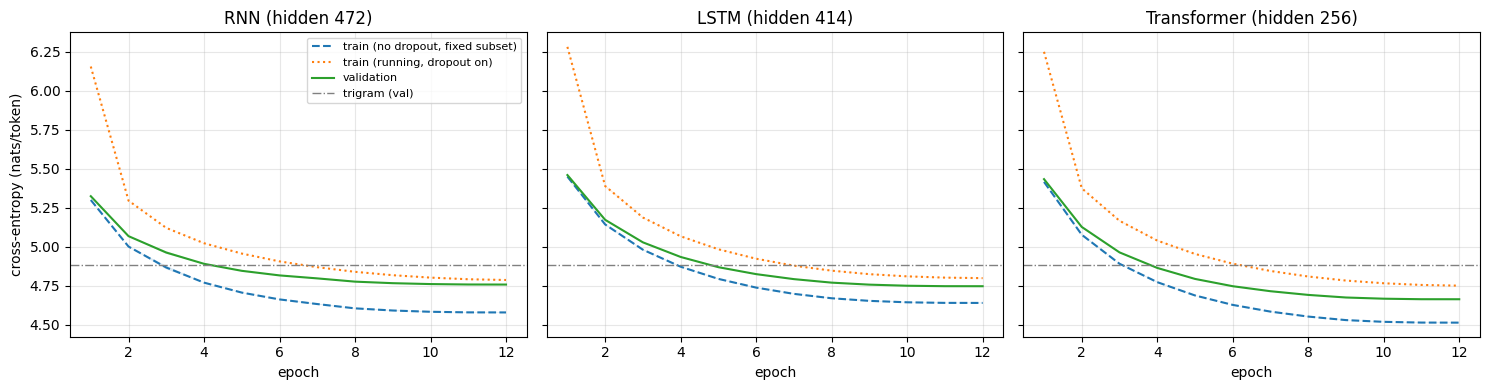

In [ ]:
# plot result
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4), sharey=True)

for ax, kind in zip(axes, KINDS):
    H_ = [runs[(kind, s)]["hist"] for s in CFG["seeds"]]
    L = min(len(h) for h in H_)
    ep = np.arange(1, L + 1)

    for col, style, lab in [("train_eval", "--", "train (no dropout, fixed subset)"), ("train_run", ":", "train (running, dropout on)"), ("val", "-", "validation")]:
        a = np.stack([h[col].values[:L] for h in H_])
        m, s = a.mean(0), a.std(0)
        ax.plot(ep, m, style, label=lab)
        ax.fill_between(ep, m - s, m + s, alpha=0.15)

    ax.axhline(ng_val_ce, color="gray", lw=1, ls="-.", label="trigram (val)")
    ax.set_title(f"{NAMES[kind]} (hidden {HID[kind]})")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("cross-entropy (nats/token)")
axes[0].legend(fontsize=8)

plt.tight_layout()
plt.savefig("figs/learning_curves.png", dpi=150)
plt.show()

### Things we can learn from I.7 (learning curves)

**All three neural models converge in a similar way.** The loss drops fast in the first 3–4 epochs and then flattens out, and by epoch 12 the curves are almost flat. Validation loss crosses below the trigram baseline (about 4.88) after roughly 4–5 epochs for every model, so even a short training budget is enough to beat the n-gram. The seed bands are barely visible, which fits the tiny ± in the results table: the curves are very stable across seeds.

**On overfitting, validation loss never turns upward in any of the three models.** The no-dropout training curve sits below validation by roughly 0.1–0.2 nats at the end, so there is a small generalisation gap, but it is not growing into a clear overfitting pattern within 12 epochs. The running training loss (dropout on) starts well above the others and ends slightly above validation, which is expected, since dropout makes the training loss look worse than it is.

**The Transformer ends with the lowest validation loss** (about 4.66, against about 4.75–4.76 for the RNN and LSTM). The final gaps are small and close to each other, so we don't read much into which model overfits "more".

Since validation is still creeping down at epoch 12, **training was stopped by the fixed budget, not by overfitting**, and we can't say what a longer run would do. Why the Transformer ends lower (attention over the full context, or its different parameter split) is only a hypothesis here. These curves show that it is lower, not why.

## I.8 Generated text
Same 5 prompts, same decoding for every model, and a fixed generation length. `<pad>`, `<unk>`, `<bos>` and `<eos>` are masked for every model, so every continuation has exactly `gen_len` real words.
- **Greedy** (argmax) exposes repetition loops.
- **Sampling** with temperature and top-k shows variety.

The sampling seed is the same for every model. The neural models are the seed-0 runs. RNN/LSTM decode with a cached hidden state. The Transformer recomputes the whole prefix at each step (no KV cache), which is part of its decoding cost here.

In [ ]:
# create 5 prompts and assign them to the 4 models
PROMPTS = ["this movie was",
           "i really wanted to like this film , but",
           "the acting was",
           "one of the best things about this",
           "if you are looking for a good horror movie"]

# convert each word into an ID according to the vocabulary (|V|)
prompt_ids = [[stoi.get(w, UNK) for w in p.split()] for p in PROMPTS]

# define how the next word is chosen
def sample_from_logits(logits, greedy, gen):
    logits = logits.clone().float()  # work on a copy
    logits[[PAD, UNK, BOS, EOS]] = -float("inf")

    if greedy: # greedy decoding -> always take the highest-scoring word
        return int(logits.argmax())

    # sampling strategy:
    logits = logits / CFG["temperature"]               # divide by the temperature
    thr = torch.topk(logits, CFG["top_k"]).values[-1]  # keep only the 40 highest-scoring words
    logits[logits < thr] = -float("inf")               # discard the rest
    x = int(torch.multinomial(F.softmax(logits, -1), 1, generator=gen)) # convert to probabilities with softmax and draw one word at random

    return x

# continue the text with the RNN/LSTM/Transformer
@torch.no_grad()
def gen_neural(model, prompt, n, greedy, seed):

    # put the model in eval mode
    model.eval()
    gen = torch.Generator().manual_seed(seed)
    seq = [BOS] + prompt
    out = []

    # make sure the prompt + 60 new words (see CFG['gen_len']) fit in the 128-token context
    assert len(seq) + n <= CFG["max_len"]

    # if the model is the Transformer
    if model.kind == "transformer":
        for _ in range(n):
            lg = model(torch.tensor([seq], device=DEVICE))[0, -1].cpu()
            w = sample_from_logits(lg, greedy, gen)
            out.append(w)
            seq.append(w)

    # if the model is an RNN/LSTM
    else:
        lg, st = model(torch.tensor([seq], device=DEVICE), return_state=True)

        # predict one word at a time, starting from the prompt
        for _ in range(n):
            w = sample_from_logits(lg[0, -1].cpu(), greedy, gen)
            out.append(w)
            lg, st = model(torch.tensor([[w]], device=DEVICE), st, True)

    return out


def gen_ngram(prompt, n, greedy, seed):
    gen = torch.Generator().manual_seed(seed)
    seq = [BOS] + prompt
    out = []

    for _ in range(n):
        u = seq[-2] if len(seq) >= 2 else BOS # -2 because the trigram looks at the last 2 words
        lg = torch.log(torch.from_numpy(ng.dist(u, seq[-1])).clamp_min(1e-30))

        # get the ID of the next word and store it in the history
        w = sample_from_logits(lg, greedy, gen)
        out.append(w)
        seq.append(w)

    return out

# measure repetition
def gen_metrics(ids):

    bg, tg = list(zip(ids, ids[1:])), list(zip(ids, ids[1:], ids[2:]))

    return dict(distinct1=len(set(ids)) / len(ids),
                distinct2=len(set(bg)) / len(bg),
                repeated_trigram=1 - len(set(tg)) / len(tg))

def detok(ids):
    return " ".join(itos[i] for i in ids)

# run one model through all the prompts
def generate_all(fn):
    """Greedy (1 per prompt, timed) and sampled (n_samples per prompt) continuations from one model."""
    fn(prompt_ids[0], True, 0)                                          # warm-up

    t0 = time.perf_counter()
    greedy = [[fn(p, True, 0)] for p in prompt_ids]      # generate 1 greedy continuation for each prompt (5 in total)
    tps = len(prompt_ids) * CFG["gen_len"] / (time.perf_counter() - t0)      # decoding speed in tokens per second at bs=1

    # then 20 sampled continuations per prompt (100 in total); each uses a different seed so the samples differ
    sample = [[fn(p, False, CFG["gen_seed"] + 1000 * i + j) for j in range(CFG["n_samples"])] for i, p in enumerate(prompt_ids)]

    return greedy, sample, tps

# run it for every model
GEN, decode_tps = {}, {}
for name in ["ngram"] + KINDS:
    model = None if name == "ngram" else runs[(name, CFG["seeds"][0])]["model"]
    fn = (lambda p, g, s: gen_ngram(p, CFG["gen_len"], g, s)) if name == "ngram" else (lambda p, g, s, m=model: gen_neural(m, p, CFG["gen_len"], g, s))
    GEN[(name, "greedy")], GEN[(name, "sample")], decode_tps[name] = generate_all(fn)

for i, p in enumerate(PROMPTS):
    print(f"\n### Prompt: {p}")
    for name in ["ngram"] + KINDS:
        print(f"[{NAMES[name]:<11}] greedy: {detok(GEN[(name, 'greedy')][i][0])}")
        print(f"{'':<14} sample: {detok(GEN[(name, 'sample')][i][0])}")

gm = {}
for (name, mode), per_prompt in GEN.items():
    gm[(NAMES[name], mode)] = pd.DataFrame([gen_metrics(c) for conts in per_prompt for c in conts]).mean()

# create the result dataframe
gen_table = pd.DataFrame(gm).T.round(3)
gen_table.index.names = ["model", "decoding"]
display(gen_table)
gen_table.to_csv("results/generation_metrics.csv")

# print the output
print(f"(lower repeated_trigram / higher distinct-n = less repetition; {CFG['n_samples']} sampled continuations x {len(PROMPTS)} prompts, {CFG['gen_len']} tokens each)")

cost["decode tok/s (bs=1)"] = [f"{decode_tps[k]:,.0f}" for k in ["ngram"] + KINDS]
print(f"Autoregressive decoding speed (batch size 1; trigram on CPU, neural models on {DEVICE}):")
display(cost[["decode tok/s (bs=1)"]])
cost.to_csv("results/cost.csv")


### Prompt: this movie was
[Trigram    ] greedy: a great movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie . the movie
               sample: made i 1975 . . and they don't care if the characters are all the way . the original " . a of comedy and this is a movie . the " , the movie is that i don't want to be a real and the same time . i do it . . . . it has a bunch
[RNN        ] greedy: a great movie . i was expecting a lot of the movie . i was expecting a lot of the movie . i was expecting a lot of the movie . i was expecting a lot of the movie . i was expecting a lot of the movie . i was expecting a lot of the movie . i was
               sample: made for a long time and i saw it . the acting was horrible : the script was great . the acting was terrible and unrealistic and the movie . the story is bad and the acti

distinct1  distinct2  repeated_trigram
model       decoding                                        
Trigram     greedy        0.063      0.064             0.934
            sample        0.621      0.926             0.019
RNN         greedy        0.203      0.231             0.752
            sample        0.614      0.905             0.034
LSTM        greedy        0.243      0.302             0.655
            sample        0.628      0.925             0.017
Transformer greedy        0.327      0.390             0.552
            sample        0.603      0.893             0.035

(lower repeated_trigram / higher distinct-n = less repetition; 20 sampled continuations x 5 prompts, 60 tokens each)
Autoregressive decoding speed (batch size 1; trigram on CPU, neural models on cuda):


,decode tok/s (bs=1)
Trigram,"2,956"
RNN,"1,887"
LSTM,"1,908"
Transformer,539


### Things we can learn from I.8 (generated text)

**With greedy decoding, every model falls into loops**, but how bad it is follows the perplexity order. **The trigram is the worst** (repeated_trigram 0.93; it basically just writes "the movie . the movie ." forever), then RNN (0.75), LSTM (0.66) and **the Transformer is the least repetitive** (0.55). The Transformer still loops too, it just repeats longer phrases ("i was expecting a good movie ... i was surprised to see it"), so greedy degeneration is not fixed by a better model, only reduced.

**With sampling, all four models look almost the same on the repetition numbers** (distinct-2 about 0.89–0.93, repeated trigram below 0.04). So **these metrics can't separate** the models here, and they don't measure quality: the trigram samples are rarely repetitive but they are not fluent at all ("made i 1975 . . and they don't care if the characters are all the way"). The neural samples are clearly better locally: grammatical sentences with believable review words ("the acting was horrible", "i saw it from the theater"). But consistency is weak for all of them: a single sample can say "it was a good movie . it was not a bad movie" or flip between good and bad, and sometimes ". . . . ." appears.

On **decoding speed** (batch size 1), **the Transformer is the slowest** (539 tok/s) vs RNN and LSTM (~1,900). We think a big part of this is our implementation: there is no KV cache, so **the full prefix is recomputed at every step**, which means this is not purely an architecture limit. So the Transformer gives the best perplexity and the least repetition, but costs the most at decoding time.

**Caveats: only the seed-0 models, 5 prompts, and the greedy rows are an average of just 5 continuations.**

## I.9 Part I answers (auto-generated from the results above)

In [ ]:
def line(s): print("-", s)
print("Q1 Models trained from scratch on one corpus")
line(f"Trigram (λ={ng.lam}) + RNN (H={HID['rnn']}), LSTM (H={HID['lstm']}), Transformer (width {HID['transformer']}, {CFG['tf_layers']} layers); random trainable embeddings (dim {CFG['emb_dim']}); context {CFG['max_len']} tokens; |V|={V}.")
line("Sanity checks passed (initial loss ≈ ln|V|, padding excluded, no future-token leakage, can overfit one batch, n-gram distribution valid): " + str(SANITY_OK) + ".")

print("\nQ2 Prediction quality")
order = qual.sort_values("test_ppl").index.tolist()
line("Test perplexity (lower is better): " + ", ".join(f"{NAMES[m]} {qual.loc[m, 'test_ppl']:.1f}" for m in order) + ".")
for a, b in zip(order, order[1:]):
    gap, sd = qual.loc[b, "test_ppl"] - qual.loc[a, "test_ppl"], max(qual.loc[a, "test_ppl_std"], qual.loc[b, "test_ppl_std"])
    verdict = ("only one seed, so no noise estimate." if len(CFG["seeds"]) < 2 else ("gap exceeds 2x seed std." if gap > 2 * sd else "NOT clearly larger than seed noise."))
    line(f"  {NAMES[a]} vs {NAMES[b]}: gap {gap:.1f} perplexity points; seed std {sd:.1f} -> " + verdict)

print("\nQ3 Training and inference cost")
pm = {k: np.mean([runs[(k, s)]["hist"].epoch_time.mean() for s in CFG["seeds"]]) for k in KINDS}
line("Training time per epoch (s): " + ", ".join(f"{NAMES[k]} {v:.1f}" for k, v in pm.items()) + f" on {'GPU' if DEVICE == 'cuda' else 'CPU'}.")
line("Parameters (total / core): " + ", ".join(f"{NAMES[k]} {n_params(runs[(k, 0)]['model']):,} / {core_params(runs[(k, 0)]['model']):,}" for k in KINDS) + f"; trigram stores {sz['stored_bigrams'] + sz['stored_trigrams']:,} n-grams.")
line("Scoring throughput (tokens/s, CPU): " + ", ".join(f"{NAMES[k]} {tput[k]['cpu']:,.0f}" for k in ['ngram'] + KINDS) + ".")
line("Decoding throughput (tokens/s, batch size 1): " + ", ".join(f"{NAMES[k]} {decode_tps[k]:,.0f}" for k in ['ngram'] + KINDS) + ".")

print("\nQ4 Learning behaviour")
for k in KINDS:
    Hs = [runs[(k, s)]["hist"] for s in CFG["seeds"]]
    best_ep = np.mean([runs[(k, s)]["best_epoch"] for s in CFG["seeds"]])
    gap = np.mean([h.val.iloc[-1] - h.train_eval.iloc[-1] for h in Hs])
    rise = np.mean([h.val.iloc[-1] - h.val.min() for h in Hs])
    late = np.mean([h.val.iloc[-4] - h.val.iloc[-1] for h in Hs]) if CFG["epochs"] >= 4 else float("nan")
    line(f"{NAMES[k]}: best validation epoch {best_ep:.1f} of {CFG['epochs']}; final val minus train(no dropout) gap {gap:+.3f}; final val is {rise:+.3f} above its minimum" + (" (overfitting)." if rise > 0.01 else " (no overfitting at this budget).")
         + ("" if late != late else f" Val still fell by {late:.3f} over the last 3 epochs" + (" -> may be budget-limited (consider more epochs)." if late > 0.02 else ".")))

print("\nQ5 Generated text (same prompts, matched decoding)")
for mode in ["greedy", "sample"]:
    r = {NAMES[k]: gen_table.loc[(NAMES[k], mode), "repeated_trigram"] for k in ["ngram"] + KINDS}
    line(f"Repeated-trigram rate, {mode}: " + ", ".join(f"{k} {v:.2f}" for k, v in sorted(r.items(), key=lambda t: t[1])) + " (lowest first). Read the excerpts above for local fluency and consistency.")

print("\nFacts for the report:")
print("  hardware:", HW)
print(f"  corpus: {CFG['corpus']} | docs {len(docs)} | |V| {V} | context {CFG['max_len']} | seeds {CFG['seeds']}")
print(f"  budget: {CFG['epochs']} epochs, batch {CFG['batch_size']}, AdamW lr {CFG['lr']} (warm-up {CFG['warmup_steps']} steps, cosine), clip {CFG['clip']}, dropout {CFG['dropout']}")
print(f"  decoding: greedy and sampling (T {CFG['temperature']}, top-k {CFG['top_k']}), {CFG['gen_len']} new tokens, <unk>/<eos> masked")

Q1 Models trained from scratch on one corpus
- Trigram (λ=(0.2, 0.45, 0.35)) + RNN (H=472), LSTM (H=414), Transformer (width 256, 3 layers); random trainable embeddings (dim 100); context 128 tokens; |V|=10004.
- Sanity checks passed (initial loss ≈ ln|V|, padding excluded, no future-token leakage, can overfit one batch, n-gram distribution valid): True.

Q2 Prediction quality
- Test perplexity (lower is better): Transformer 105.7, LSTM 114.8, RNN 116.0, Trigram 132.6.
-   Transformer vs LSTM: gap 9.1 perplexity points; seed std 0.3 -> gap exceeds 2x seed std.
-   LSTM vs RNN: gap 1.2 perplexity points; seed std 0.3 -> gap exceeds 2x seed std.
-   RNN vs Trigram: gap 16.6 perplexity points; seed std 0.1 -> gap exceeds 2x seed std.

Q3 Training and inference cost
- Training time per epoch (s): RNN 16.9, LSTM 17.7, Transformer 21.2 on GPU.
- Parameters (total / core): RNN 6,003,220 / 270,928, LSTM 6,006,556 / 854,496, Transformer 5,999,844 / 2,428,416; trigram stores 2,249,960 n-grams.
-

### What we can infer from the Part I results

- **Prediction quality:** Transformer (105.7) < LSTM (114.8) < RNN (116.0) < Trigram (132.6). Every gap is bigger than 2x the seed std, so it is not seed noise. LSTM vs RNN is only 1.2 points, a small gain.
  
- **Cost:** total parameters are matched (~6.0M) but the core is not: RNN 0.27M, LSTM 0.85M, Transformer 2.43M. The Transformer takes ~25% more training time per epoch than RNN (21.2 s vs 16.9 s) and decodes 3.5x slower (539 vs ~1,900 tok/s). The trigram scores about 28–34x faster than the neural models (on CPU), but its decoding is only ~1.6x faster than the RNN.
  
- **Learning and generation:** no overfitting within 12 epochs, and greedy repetition follows the perplexity order (see I.7 and I.8).
  
- **Trade-off:** the Transformer gives the best quality and least repetition but is the most expensive. LSTM costs about the same as RNN for a small gain, and the trigram is far cheaper but about 25% worse in perplexity (132.6 vs 105.7).

## I.10 Interpretation - Trade-offs

**What we saw:** better prediction costs more. The Transformer has the lowest perplexity but is the slowest to train and the slowest to decode. The LSTM is only a bit better than the RNN and costs about the same. The trigram is much worse (about 25% higher perplexity than the Transformer: 132.6 vs 105.7), but it is very cheap to score.

**Why, maybe:** the Transformer may win because it can look directly at every earlier token, and the neural models in general can share information between similar words, while the trigram only matches exact word pairs. These are just guesses; we did not test them.

**What limits the conclusion:** the models are matched on total parameters, but the core is very different (the Transformer's is about 9x the RNN's), so we can't say if the gain is from the architecture or from the bigger core. The trigram also sees only 2 previous words, so context length could explain its gap. All models got the same 12-epoch budget and were still improving, and the Transformer decodes slowly partly because we have no KV cache. So the ranking is solid for this setup, but the reasons behind it are not proven.

# PART II: Embedding variants and ablation (30 points)

## Questions from the brief
Select **one** neural architecture from Part I and compare three input-embedding settings, keeping the embedding dimension, architecture, data and training procedure the same:
1. **Random, trainable:** randomly initialised embeddings learned jointly with the LM (reuse the Part I model).
2. **Own, frozen:** embeddings trained by yourself on the training corpus (Skip-gram, CBOW or GloVe) and then kept fixed.
3. **Public, frozen:** public pretrained embeddings (GloVe) kept fixed. Document vocabulary coverage and how missing words are initialised. Keep the **entire** table fixed.
4. **Compare** test prediction quality, convergence, training stability and representative generated text.
5. **Report the cost** of training your own embeddings separately from LM training.
6. **Interpret** in light of both embedding trainability and the additional training data used by public embeddings.

## How the cells below answer them
| Question | Section | Evidence produced |
|---|---|---|
| Architecture choice | II.1 | Rule: lowest mean **validation** loss among Part I architectures (no test peeking); override with `p2_arch` |
| 1 Random, trainable | II.2 | Reuses the Part I runs (same dimension, architecture, data, procedure, seeds) |
| 2 Own, frozen | II.1, II.2 | Skip-gram with negative sampling on the training split only; table frozen |
| 3 Public, frozen | II.1, II.2 | GloVe 6B 100d; coverage table (types and tokens); contraction handling; random init for missing words; table frozen |
| "Entire table fixed" | II.2 | `requires_grad=False` plus an assertion after training that the table equals its initial value |
| 4 Compare | II.3 to II.5 | Test CE/perplexity (mean ± std), epochs to a common loss, gradient/clipping stability, curves, same prompts and decoding |
| 5 Embedding cost | II.1 | Separate table: Skip-gram time and tokens; GloVe load time and its pretraining data size |
| 6 Interpretation | II.5, II.6 | **Control run** (random, frozen) separates "frozen" from "pretrained"; the comparison chain is spelled out |

## II.1 Choose the architecture and build the embedding tables
- **Skip-gram (own):** gensim word2vec, negative sampling, trained on the **training split only** (tokens as encoded for the LM, including `<unk> <bos> <eos>`). One run, fixed seed, one worker so it is reproducible.
- **GloVe (public):** 6B tokens (Wikipedia 2014 + Gigaword 5), 100 dimensions. GloVe tokenises contractions as pieces ("don't" is "do" + "n't"), while our tokenizer keeps "don't" whole. For such words the vector is the **mean of the pieces**. Words still missing, and `<unk> <bos> <eos>`, get **random vectors drawn with GloVe's overall mean and std** (fixed, seeded). `<pad>` is the zero vector.
- **Scale:** the trainable random table starts at std 1 (PyTorch default). Both frozen tables are divided by their overall std so all three start on the same scale, instead of leaving scale as a hidden difference.

In [ ]:
try:
    import gensim
except ModuleNotFoundError:                      # Colab does not ship gensim: install it once, then import
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gensim"])
    import gensim
from gensim.models import Word2Vec, KeyedVectors
print("gensim", gensim.__version__)
# embedding dimension (100, the same as the Part I models)
D_EMB = CFG["emb_dim"]

# ---- which architecture? lowest mean VALIDATION loss among Part I models (the test set is not used)
val_by_arch = {k: float(np.mean([runs[(k, s)]["val_best"] for s in CFG["seeds"]])) for k in KINDS}
P2 = min(val_by_arch, key=val_by_arch.get) if CFG["p2_arch"] == "auto" else CFG["p2_arch"]
print("Mean validation CE per Part I architecture:", {NAMES[k]: round(v, 3) for k, v in val_by_arch.items()})
print(f"Part II architecture: {NAMES[P2]}" + (" (auto: lowest validation loss)" if CFG["p2_arch"] == "auto" else " (set in CFG)"))

# ---- own embeddings: Skip-gram with negative sampling on the training split only
# turn every training sequence back into a list of words for gensim
sg_sentences = [[itos[i] for i in s] for s in data["train"]]
n_sg_tokens = sum(len(s) for s in sg_sentences)

# train Skip-gram and time it
t0 = time.perf_counter()
w2v = Word2Vec(sg_sentences, vector_size=D_EMB, window=CFG["sg_window"], min_count=1, sg=1, negative=CFG["sg_negative"],
               epochs=CFG["sg_epochs"], workers=1, seed=CFG["sg_seed"], hashfxn=lambda s: zlib.crc32(str(s).encode("utf8")))
sg_time = time.perf_counter() - t0

# fixed random generator for the words that have no vector
rng_fill = np.random.RandomState(CFG["sg_seed"])

# fill the Skip-gram table row by row (row 0 = <pad> stays zero)
E_sg = np.zeros((V, D_EMB), np.float32)
sg_missing = []
for i, w in enumerate(itos):
    if i == PAD: continue
    if w in w2v.wv.key_to_index: E_sg[i] = w2v.wv[w]
    else: sg_missing.append(i)                       # e.g. <unk> if the training split has no out-of-vocabulary word

# words without a Skip-gram vector get random vectors with the same std
if sg_missing: E_sg[sg_missing] = rng_fill.normal(0, float(w2v.wv.vectors.std()), size=(len(sg_missing), D_EMB))

# ---- public embeddings: GloVe 6B 100d
# load GloVe from a local file or download it with gensim
def load_glove():
    if CFG["glove_path"]:
        return KeyedVectors.load_word2vec_format(CFG["glove_path"], binary=False, no_header=True)
    import gensim.downloader as api
    return api.load(CFG["glove_name"])

# load GloVe and time it
t0 = time.perf_counter()
kv = load_glove()
glove_time = time.perf_counter() - t0

# GloVe must have the same dimension as our embeddings
assert kv.vector_size == D_EMB, "GloVe dimension must equal emb_dim"

# contractions that GloVe splits into pieces, e.g. don't -> do + n't
CONTR = re.compile(r"^(.+?)(n't|'s|'m|'re|'ve|'ll|'d)$")

# look up one word: directly, via contraction pieces, or missing
def glove_lookup(w):
    if w in kv.key_to_index: return kv[w], "direct"

    m_ = CONTR.match(w)
    if m_ and all(p in kv.key_to_index for p in m_.groups()):
        return np.mean([kv[p] for p in m_.groups()], 0), "pieces"       # "don't" -> mean(do, n't)
    return None, "missing"

# overall mean and std of GloVe, used to draw vectors for the missing words
g_mean, g_std = float(kv.vectors.mean()), float(kv.vectors.std())

# fill the GloVe table row by row
E_gl = np.zeros((V, D_EMB), np.float32)
how = {}
for i, w in enumerate(itos):
    if i == PAD: continue
    vec, h = (None, "missing") if i < len(SPECIALS) else glove_lookup(w)       # special tokens are never looked up
    how[i] = h
    if vec is not None: E_gl[i] = vec

# list the words that GloVe does not have
miss = [i for i, h in how.items() if h == "missing"]
E_gl[miss] = rng_fill.normal(g_mean, g_std, size=(len(miss), D_EMB))           # fixed random init for missing words

# coverage is measured on real words only (special tokens excluded)
real = [i for i in how if i >= len(SPECIALS)]

# training frequency of every real word
tok_n = {i: counts[itos[i]] for i in real}
tok_all = sum(tok_n.values())

# coverage table: share of vocabulary types and share of training tokens
cov_table = pd.DataFrame({h: {"vocabulary types": sum(how[i] == h for i in real) / len(real),
                              "training tokens": sum(tok_n[i] for i in real if how[i] == h) / tok_all}
                          for h in ("direct", "pieces", "missing")}).T.rename(columns=lambda c: c + " (share)")
cov_table.index = ["found directly", "found via contraction pieces", "missing -> random init"]

# show the coverage table
display(cov_table.round(4))

# the most frequent words that GloVe does not have
top_missing = sorted([i for i in real if how[i] == "missing"], key=lambda i: -tok_n[i])[:15]
print("Most frequent words missing from GloVe:", [itos[i] for i in top_missing])
print("Special tokens <unk> <bos> <eos>: random GloVe-statistics init; <pad>: zeros.")

# ---- put all three tables on the same scale (std 1, like the default random init)
def unit_scale(E):

    # divide by the std of all real rows (row 0 = <pad> is excluded)
    s = float(E[1:].std())

    return (E / s).astype(np.float32), s

# apply the scaling to both tables and keep the scale factors
E_sg, sg_scale = unit_scale(E_sg)
E_gl, gl_scale = unit_scale(E_gl)

# check the std before and after scaling
display(pd.DataFrame({"std before scaling": {"Skip-gram (own)": sg_scale, "GloVe (public)": gl_scale, "random (default init)": 1.0},
                      "std after scaling": {"Skip-gram (own)": float(E_sg[1:].std()), "GloVe (public)": float(E_gl[1:].std()), "random (default init)": 1.0}}).round(3))

# ---- cost of obtaining the embeddings, reported separately from LM training
emb_cost = pd.DataFrame([
    {"embedding": "Skip-gram (own)", "wall time (s)": round(sg_time, 1), "text used": f"{n_sg_tokens:,} tokens x {CFG['sg_epochs']} epochs (our training split)",
     "settings": f"dim {D_EMB}, window {CFG['sg_window']}, negatives {CFG['sg_negative']}, 1 worker"},
    {"embedding": "GloVe (public)", "wall time (s)": round(glove_time, 1), "text used": "~6 billion tokens (Wikipedia 2014 + Gigaword 5), trained by others",
     "settings": f"load/download only; pretraining data is about {6e9 / n_sg_tokens:,.0f}x our training text"}]).set_index("embedding")

# show the cost table
display(emb_cost)

gensim 4.4.0
Mean validation CE per Part I architecture: {'RNN': 4.759, 'LSTM': 4.748, 'Transformer': 4.664}
Part II architecture: Transformer (auto: lowest validation loss)
[==================================================] 100.0% 128.1/128.1MB downloaded


,vocabulary types (share),training tokens (share)
found directly,0.9822,0.9853
found via contraction pieces,0.0173,0.0146
missing -> random init,0.0005,0.0000


Most frequent words missing from GloVe: ['imho', 'snowblood', 'nukie', 'nanon', 'xtro']
Special tokens <unk> <bos> <eos>: random GloVe-statistics init; <pad>: zeros.


,std before scaling,std after scaling
Skip-gram (own),0.211,1.0
GloVe (public),0.518,1.0
random (default init),1.000,1.0


,wall time (s),text used,settings
embedding,,,
Skip-gram (own),83.2,"3,303,518 tokens x 5 epochs (our training split)","dim 100, window 5, negatives 5, 1 worker"
GloVe (public),57.9,"~6 billion tokens (Wikipedia 2014 + Gigaword 5), trained by others","load/download only; pretraining data is about 1,816x our training text"


### Things we can learn from II.1

**GloVe covers almost the whole vocabulary.** 98.2% of word types are found directly and 1.7% through contraction pieces. Only about 0.05% of types (5 words: imho, snowblood, nukie, nanon, xtro) start with random vectors, and they cover almost none of the training tokens. So missing words are not a real factor in Part II.

**The two tables had very different scales, so we rescaled them.** The raw std was 0.21 for Skip-gram and 0.52 for GloVe, against 1.0 for the default random table. After dividing by the std, all three start at std 1, so scale is not a hidden difference. It is still a choice we made, and another scale could change the numbers.

**Our own embeddings are cheap, and the public ones are not "free".** Skip-gram took 83 s on 3.3M tokens (5 epochs), about a third of one Transformer run (255 s). GloVe took 58 s, but that is mostly the download, and the real training cost was paid by others on about 1,816x more text than ours. So the two times are not a like-for-like training cost, and the size of the pretraining data is the fairer comparison.


## II.2 Train the settings (3 seeds each)

In [ ]:
# the settings we compare: only the embedding table (and frozen or not) differs
P2_SETTINGS = {                                # run label -> (display name, embedding table or None, frozen?)
    P2:             (f"{NAMES[P2]} · random, trainable (Part I)", None, False),
    f"{P2}__sg":    (f"{NAMES[P2]} · Skip-gram (own), frozen", E_sg, True),
    f"{P2}__glove": (f"{NAMES[P2]} · GloVe (public), frozen", E_gl, True),
}
# optional control: random embeddings that are also frozen
if CFG["p2_control"]:
    P2_SETTINGS[f"{P2}__rf"] = (f"{NAMES[P2]} · random, frozen (control)", None, True)

# train every setting with 3 seeds (setting 1 reuses the Part I runs)
for label, (disp, E, frz) in P2_SETTINGS.items():
    DISPLAY[label] = disp
    if label == P2: continue                   # setting 1 = the Part I runs (same dimension, architecture, data, procedure, seeds)
    for seed in CFG["seeds"]:
        runs[(label, seed)] = train_model(P2, seed, name=label, emb=E, freeze=frz)

# the three required settings must differ only in the embedding table
for label in P2_SETTINGS:
    for seed in CFG["seeds"]:
        r = runs[(label, seed)]
        assert r["model"].emb.weight.shape == (V, D_EMB) and r["kind"] == P2

# train_model already asserted that the frozen tables never changed
print("Fixed tables verified unchanged after training for:", [DISPLAY[l] for l in P2_SETTINGS if runs[(l, CFG['seeds'][0])]['frozen']])

Transformer · Skip-gram (own), frozen seed 0 ep  1 | train 6.086 | train(eval) 5.146 | val 5.176 | 21.2s
Transformer · Skip-gram (own), frozen seed 0 ep  2 | train 5.162 | train(eval) 4.825 | val 4.889 | 21.2s
Transformer · Skip-gram (own), frozen seed 0 ep  3 | train 4.980 | train(eval) 4.672 | val 4.760 | 21.0s
Transformer · Skip-gram (own), frozen seed 0 ep  4 | train 4.878 | train(eval) 4.573 | val 4.681 | 21.0s
Transformer · Skip-gram (own), frozen seed 0 ep  5 | train 4.808 | train(eval) 4.499 | val 4.622 | 21.1s
Transformer · Skip-gram (own), frozen seed 0 ep  6 | train 4.758 | train(eval) 4.446 | val 4.583 | 21.3s
Transformer · Skip-gram (own), frozen seed 0 ep  7 | train 4.718 | train(eval) 4.408 | val 4.557 | 21.2s
Transformer · Skip-gram (own), frozen seed 0 ep  8 | train 4.688 | train(eval) 4.386 | val 4.542 | 21.1s
Transformer · Skip-gram (own), frozen seed 0 ep  9 | train 4.665 | train(eval) 4.365 | val 4.527 | 21.1s
Transformer · Skip-gram (own), frozen seed 0 ep 10 | tr

## II.3 Compare: test quality, convergence and stability
- **Quality:** test cross-entropy and perplexity on the same targets as Part I (each new model is evaluated once).
- **Convergence:** validation loss after epoch 1, and the first epoch at which a setting's mean validation loss reaches a **common threshold** (the worst setting's best loss, so every setting reaches it).
- **Stability:** seed-to-seed spread of the test loss, share of steps where the gradient norm exceeded the clipping threshold, largest gradient norm seen, and number of epochs where validation loss rose.

In [ ]:
for label in P2_SETTINGS:                                       # LM test set, once per new model
    for seed in CFG["seeds"]:
        if (label, seed) not in test_ce:
            # score the new model on the same test targets as Part I
            ce, n = evaluate(runs[(label, seed)]["model"], data["test"])
            assert n == n_test
            test_ce[(label, seed)] = ce

seeds = CFG["seeds"]

# number of epochs shared by all runs
Lmin = min(len(runs[(l, s)]["hist"]) for l in P2_SETTINGS for s in seeds)

# mean validation loss per epoch for every setting (over seeds)
mean_val = {l: np.mean([runs[(l, s)]["hist"].val.values[:Lmin] for s in seeds], 0) for l in P2_SETTINGS}
tau = max(v.min() for v in mean_val.values())                   # common threshold every setting reaches

# test perplexity per seed
PPL2 = {l: np.exp([test_ce[(l, s)] for s in seeds]) for l in P2_SETTINGS}

# build one table row per setting
rows2 = []
for l, (disp, E, frz) in P2_SETTINGS.items():

    # the runs and the test losses of this setting (one per seed)
    R = [runs[(l, s)] for s in seeds]
    ces = [test_ce[(l, s)] for s in seeds]

    # quality, convergence and stability numbers of this setting
    rows2.append({"setting": disp, "trainable params": f"{R[0]['n_trainable']:,}", "total params": f"{R[0]['n_total']:,}",
                  "test CE": ms(ces), "test perplexity": ms(PPL2[l], 1),
                  "val CE after epoch 1": round(float(mean_val[l][0]), 3),
                  f"epochs to val ≤ {tau:.3f}": int(np.argmax(mean_val[l] <= tau)) + 1,
                  "best epoch": ms([r["best_epoch"] for r in R], 1),
                  "clipped steps (%)": round(100 * float(np.mean([r["hist"].clip_frac.mean() for r in R])), 1),
                  "max grad norm": round(float(max(r["hist"].gn_max.max() for r in R)), 2),
                  "val-loss rises (epochs)": round(float(np.mean([(r["hist"].val.diff() > 0).sum() for r in R])), 1)})

# create the table, show it and save it as csv
table2 = pd.DataFrame(rows2).set_index("setting")
display(table2)
table2.to_csv("results/part2_quality_convergence_stability.csv")

print(f"{n_test} test targets per model; ± = std across seeds {seeds}; clipping threshold {CFG['clip']}.")

,trainable params,total params,test CE,test perplexity,val CE after epoch 1,epochs to val ≤ 4.758,best epoch,clipped steps (%),max grad norm,val-loss rises (epochs)
setting,,,,,,,,,,
"Transformer · random, trainable (Part I)","5,999,844","5,999,844",4.661 ± 0.002,105.7 ± 0.2,5.435,6,11.7 ± 0.6,0.6,1.55,0.3
"Transformer · Skip-gram (own), frozen","4,999,444","5,999,844",4.521 ± 0.005,91.9 ± 0.5,5.177,4,11.7 ± 0.6,0.9,1.58,0.3
"Transformer · GloVe (public), frozen","4,999,444","5,999,844",4.587 ± 0.002,98.2 ± 0.2,5.341,5,11.7 ± 0.6,1.0,1.58,0.3
"Transformer · random, frozen (control)","4,999,444","5,999,844",4.756 ± 0.005,116.3 ± 0.6,5.515,12,11.7 ± 0.6,0.6,1.55,0.3


182547 test targets per model; ± = std across seeds [0, 1, 2]; clipping threshold 1.0.


### Things we can learn from the II.3 table

**Both informative frozen tables beat the Part I baseline, and random frozen is the worst.** Test perplexity is Skip-gram 91.9, GloVe 98.2, random trainable 105.7 and random frozen 116.3. Every gap is much larger than the seed std (0.2 to 0.6), so this is not seed noise.

**Freezing alone costs perplexity, but what is inside the table matters more.** Random frozen is 10.6 points worse than random trainable, so being able to train the table helps. But Skip-gram frozen is 24.4 points better than random frozen. Both informative tables beat the trainable one even though they cannot move, so freezing did not hurt here.

**The pretrained tables converge faster.** Validation loss after epoch 1 is 5.18 (Skip-gram) and 5.34 (GloVe) against 5.44 for trainable, and Skip-gram reaches the common threshold in 4 epochs against 6. The "12" for random frozen is by construction: the threshold (4.758) is that setting's own best loss, so it can only reach it at its last epoch.

**Training is stable in all four settings.** Clipped steps are at most 1% and the largest gradient norm is about 1.6 everywhere (clip at 1.0). Validation loss rose in only 0.3 epochs on average. The frozen pretrained tables clip a little more often (0.9 to 1.0% against 0.6%), but the difference is tiny.

**Caveats.** Skip-gram was trained once, so its own variance is not inside the ±. The frozen settings also have 1M fewer trainable parameters (5.0M against 6.0M). Why Skip-gram beats GloVe with about 1,800x less text is only a hypothesis: its vectors come from the same reviews and the same tokenisation (no missing words, no contraction pieces), while GloVe comes from Wikipedia and news. We did not test this, and the two also differ in method.


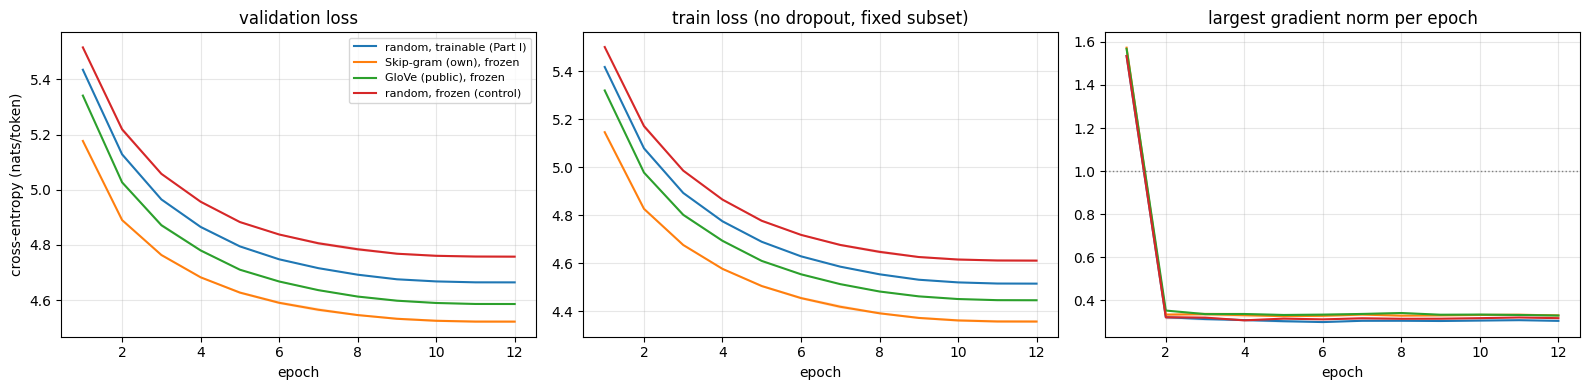

In [ ]:
# plot validation loss, train loss and largest gradient norm for each setting
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
for l, (disp, E, frz) in P2_SETTINGS.items():

    # histories of the 3 seeds of this setting
    H_ = [runs[(l, s)]["hist"] for s in seeds]
    ep = np.arange(1, Lmin + 1)

    # one panel per quantity
    for ax, col, ttl in [(axes[0], "val", "validation loss"), (axes[1], "train_eval", "train loss (no dropout, fixed subset)"), (axes[2], "gn_max", "largest gradient norm per epoch")]:

        # mean and std over the seeds
        a = np.stack([h[col].values[:Lmin] for h in H_])
        m, s = a.mean(0), a.std(0)

        # draw the mean curve with a seed band (mean ± std)
        ax.plot(ep, m, label=disp.split(" · ")[1])
        ax.fill_between(ep, m - s, m + s, alpha=0.15)
        ax.set_title(ttl)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)

# mark the clipping threshold on the gradient panel
axes[2].axhline(CFG["clip"], color="gray", ls=":", lw=1)
axes[0].legend(fontsize=8)
axes[0].set_ylabel("cross-entropy (nats/token)")

# save the figure and show it
plt.tight_layout()
plt.savefig("figs/part2_curves.png", dpi=150)
plt.show()

### Things we can learn from the II.3 curves

**The four settings never cross.** The validation curves keep the same order from epoch 1 to 12 (Skip-gram, GloVe, trainable, random frozen), so the table ranking is not caused by one lucky epoch. The gap between Skip-gram and trainable shrinks from about 0.26 nats at epoch 1 to about 0.15 at epoch 12, so the trainable table is catching up, but within 12 epochs it has not.

**Train loss has the same order as validation loss.** The informative frozen tables also give a lower training loss (4.35 for Skip-gram against 4.51 for trainable, no dropout, seed 0), so they help the model fit the data and not only generalise. The final validation minus train gap is similar in all four (0.14 to 0.17 nats, largest for Skip-gram) and validation never turns up, so we see no overfitting at this budget.

**Gradient norms only spike in epoch 1.** The largest gradient norm is about 1.55 in epoch 1, above the clip line of 1.0, and then stays around 0.3 in every setting. So clipping happens early (during warm-up), which fits the small clipped-step share in the table. No setting looks unstable.

**Training is again stopped by the budget.** All curves are flattening but still creep down at epoch 12, the same as in Part I, so we cannot say where they would end with a longer run.


## II.4 Representative generated text
The same prompts, decoding settings and lengths as Part I, from the seed-0 model of each setting.

In [ ]:
# generate text from the seed-0 model of every setting (same prompts and decoding as Part I)
GEN2 = {}
for l in P2_SETTINGS:
    m_ = runs[(l, CFG["seeds"][0])]["model"]

    # generation function of this model (m=m_ binds the current model)
    fn = lambda p, g, s, m=m_: gen_neural(m, p, CFG["gen_len"], g, s)

    # 1 greedy and 20 sampled continuations per prompt
    GEN2[(l, "greedy")], GEN2[(l, "sample")], _ = generate_all(fn)

# print the continuations prompt by prompt
for i, p in enumerate(PROMPTS):
    print(f"\n### Prompt: {p}")

    for l in P2_SETTINGS:
        tag = DISPLAY[l].split(" · ")[1]
        print(f"[{tag:<28}] greedy: {detok(GEN2[(l, 'greedy')][i][0])}")
        print(f"{'':<31} sample: {detok(GEN2[(l, 'sample')][i][0])}")

# repetition metrics, averaged over all continuations
gm2 = {(DISPLAY[l].split(" · ")[1], mode): pd.DataFrame([gen_metrics(c) for conts in per for c in conts]).mean() for (l, mode), per in GEN2.items()}

# create the result table
gen_table2 = pd.DataFrame(gm2).T.round(3)
gen_table2.index.names = ["setting", "decoding"]

# show the table and save it as csv
display(gen_table2)
gen_table2.to_csv("results/part2_generation_metrics.csv")


### Prompt: this movie was
[random, trainable (Part I)  ] greedy: a great movie . i was expecting a good movie . i was expecting a good movie . i was expecting a good movie . i was really disappointed . i was expecting a good movie . i was hoping to see it . i was very disappointed . i was expecting a lot of people who were in the
                                sample: made for a long time and i saw it from the theater as my favorite film . it was a great film . i was pleased for the movie . the first time i saw the dvd i was amazed , i was surprised to the same thing . i was so excited that i just loved the movie at
[Skip-gram (own), frozen     ] greedy: a great movie . i was expecting a lot of fun and fun to watch it . i was expecting a lot of fun and fun to watch it . i was surprised to see it again . i was a huge fan of the movie and i was surprised to see it . i was surprised to see it
                                sample: a pretty bad . i did really think that it was an excel

distinct1  distinct2  repeated_trigram
setting                    decoding                                        
random, trainable (Part I) greedy        0.327      0.390             0.552
                           sample        0.603      0.893             0.035
Skip-gram (own), frozen    greedy        0.217      0.288             0.676
                           sample        0.591      0.880             0.044
GloVe (public), frozen     greedy        0.347      0.464             0.490
                           sample        0.568      0.851             0.073
random, frozen (control)   greedy        0.233      0.302             0.659
                           sample        0.603      0.881             0.054

### Things we can learn from II.4

**Greedy decoding loops in every setting, and the repetition ranking is not the perplexity ranking.** The repeated-trigram rate is GloVe 0.49, trainable 0.55, random frozen 0.66 and Skip-gram 0.68. Skip-gram has the best perplexity but loops more than the Part I baseline, so a lower perplexity does not mean less greedy repetition. The loops are often the same phrase across settings ("the acting was terrible . the acting was horrible ..."), and each setting has its own favourite ("i was very disappointed" for random frozen, "i have seen it again" for Skip-gram).

**With sampling, the numbers hardly separate the settings.** Repeated trigram is 0.04 to 0.07 and distinct-2 is 0.85 to 0.89. GloVe is the most repetitive here (0.073, lowest distinct-2). Reading the text, the Skip-gram sample on the first prompt repeats one template ("the acting was terrible . the acting is bad . the acting was terrible") but stays consistently negative, while the GloVe sample drifts into plot talk ("the story is the story of the book and the story of a young girl ...").

**Local fluency is about the same and consistency is weak everywhere.** Most samples are grammatical short phrases that drift in topic and sentiment ("the acting was horrible : a lot of the direction that was great"), and runs of ". . . . ." appear in several settings. Some samples also start identically across models (trainable and GloVe on the first prompt) because we use the same sampling seed for every model, so they are not independent evidence.

**Caveats:** only the seed-0 models, 5 prompts, and greedy rows that average just 5 continuations. Differences such as 0.55 against 0.49 are weak evidence, and the repetition metrics do not measure fluency.


## II.5 Part II answers (auto-generated from the results above)

In [ ]:
# compare two settings by test perplexity
def cmp(a, b):
    """Compare two settings by test perplexity: mean difference vs 2x the larger seed std."""
    # test perplexity of both settings (one value per seed)
    pa, pb = PPL2[a], PPL2[b]
    gap = pa.mean() - pb.mean()
    sd = max(pa.std(ddof=1), pb.std(ddof=1)) if len(pa) > 1 else float("nan")
    flag = "only one seed" if sd != sd else ("larger than 2x seed std" if abs(gap) > 2 * sd else "within seed noise")
    return f"{DISPLAY[a].split(' · ')[1]} vs {DISPLAY[b].split(' · ')[1]}: {gap:+.1f} perplexity ({flag})"

# architecture and the fixed setup
print(f"Architecture: {NAMES[P2]}; embedding dim {D_EMB}; same data, procedure and seeds in every setting.")
print("\nQ1-3 Test prediction quality")

# rank the settings by mean test perplexity
order2 = sorted(P2_SETTINGS, key=lambda l: PPL2[l].mean())
line("Test perplexity (lower is better): " + ", ".join(f"{DISPLAY[l].split(' · ')[1]} {PPL2[l].mean():.1f}" for l in order2) + ".")

# convergence and stability (numbers from the II.3 table)
print("\nQ4 Convergence and stability")
line(f"Validation loss after epoch 1: " + ", ".join(f"{DISPLAY[l].split(' · ')[1]} {mean_val[l][0]:.3f}" for l in P2_SETTINGS) + ".")
line(f"Epochs to reach val ≤ {tau:.3f}: " + ", ".join(f"{DISPLAY[l].split(' · ')[1]} {int(np.argmax(mean_val[l] <= tau)) + 1}" for l in P2_SETTINGS) + ".")
line("Share of clipped steps (%) / max gradient norm: " + ", ".join(f"{DISPLAY[l].split(' · ')[1]} {table2.loc[DISPLAY[l], 'clipped steps (%)']} / {table2.loc[DISPLAY[l], 'max grad norm']}" for l in P2_SETTINGS) + ".")

# repetition in the generated text
print("\nQ4 Generated text")
for mode in ["greedy", "sample"]:
    r = {DISPLAY[l].split(' · ')[1]: gen_table2.loc[(DISPLAY[l].split(' · ')[1], mode), "repeated_trigram"] for l in P2_SETTINGS}
    line(f"Repeated-trigram rate, {mode}: " + ", ".join(f"{k} {v:.2f}" for k, v in sorted(r.items(), key=lambda t: t[1])) + " (lowest first).")

# cost of the embeddings (separate from LM training)
print("\nQ5 Cost of obtaining embeddings (reported separately from LM training)")
line(f"Skip-gram: {sg_time:.1f}s on {n_sg_tokens:,} tokens x {CFG['sg_epochs']} epochs. GloVe: {glove_time:.1f}s to load; pretrained on ~6B tokens (≈{6e9 / n_sg_tokens:,.0f}x our training text).")
line(f"GloVe coverage: {cov_table.iloc[0, 0] + cov_table.iloc[1, 0]:.1%} of vocabulary types and {cov_table.iloc[0, 1] + cov_table.iloc[1, 1]:.1%} of training tokens have a GloVe vector ({cov_table.iloc[1, 0]:.1%} of types via contraction pieces); the rest start random and stay fixed.")

# interpretation chain: each comparison changes only one factor
print("\nQ6 Interpretation chain (each line isolates one factor)")
# run labels: trainable baseline, Skip-gram frozen, GloVe frozen
tr, sgf, gl = P2, f"{P2}__sg", f"{P2}__glove"
# with the control we can separate trainability from pretrained structure
if CFG["p2_control"]:
    rf = f"{P2}__rf"
    line("Trainability alone (random trainable vs random frozen): " + cmp(tr, rf))
    line("Structure learned from our own text, frozen (Skip-gram vs random frozen): " + cmp(sgf, rf))
line("Own frozen vs trainable (what freezing costs when the vectors are informative): " + cmp(sgf, tr))
line("Extra pretraining data (GloVe vs Skip-gram, both frozen; the method also differs): " + cmp(gl, sgf))
line("Public frozen vs the Part I baseline: " + cmp(gl, tr))

Architecture: Transformer; embedding dim 100; same data, procedure and seeds in every setting.

Q1-3 Test prediction quality
- Test perplexity (lower is better): Skip-gram (own), frozen 91.9, GloVe (public), frozen 98.2, random, trainable (Part I) 105.7, random, frozen (control) 116.3.

Q4 Convergence and stability
- Validation loss after epoch 1: random, trainable (Part I) 5.435, Skip-gram (own), frozen 5.177, GloVe (public), frozen 5.341, random, frozen (control) 5.515.
- Epochs to reach val ≤ 4.758: random, trainable (Part I) 6, Skip-gram (own), frozen 4, GloVe (public), frozen 5, random, frozen (control) 12.
- Share of clipped steps (%) / max gradient norm: random, trainable (Part I) 0.6 / 1.55, Skip-gram (own), frozen 0.9 / 1.58, GloVe (public), frozen 1.0 / 1.58, random, frozen (control) 0.6 / 1.55.

Q4 Generated text
- Repeated-trigram rate, greedy: GloVe (public), frozen 0.49, random, trainable (Part I) 0.55, random, frozen (control) 0.66, Skip-gram (own), frozen 0.68 (lowest f

### What we can infer from the Part II results

- **Prediction quality:** Skip-gram (91.9) < GloVe (98.2) < random trainable (105.7) < random frozen (116.3). Every gap is bigger than 2x the seed std.

- **Convergence and stability:** Skip-gram reaches the common threshold in 4 epochs, GloVe in 5, trainable in 6 and random frozen in 12. Clipping touches at most 1% of steps and the largest gradient norm is about 1.6 in every setting, so no setting is unstable.

- **Generated text:** greedy repetition does not follow perplexity (GloVe 0.49 is the lowest, Skip-gram 0.68 the highest). With sampling every setting stays below 0.08.

- **Cost:** Skip-gram took 83 s on our own 3.3M tokens. GloVe took 58 s to load and was pretrained on about 1,816x more text. GloVe covers 99.9% of the vocabulary types.

- **Chain of comparisons:** trainability alone is worth 10.6 perplexity points (random trainable vs random frozen) and structure from our own text is worth 24.4 (Skip-gram vs random frozen). Freezing informative vectors still beats training random ones (-13.8). GloVe is 6.2 points worse than Skip-gram and 7.5 better than the baseline.


## II.6 Interpretation - Embedding trainability vs extra data

**What we saw:** what is inside the embedding table matters more than whether the table can be trained. Frozen Skip-gram (91.9) and frozen GloVe (98.2) both beat the trainable random baseline (105.7), while frozen random vectors are the worst (116.3). The informative tables also converge faster and are just as stable. Our own Skip-gram, trained on about 3.3M tokens, beat GloVe, which saw about 1,816x more text.

**Why, maybe:** the pretrained tables give the model word similarity from step 0, so the loss is lower after epoch 1 and the curves never cross. A trainable table has to learn that from the next-token loss alone, and rare words get few updates. Skip-gram may beat GloVe because it matches our domain (same reviews, same tokenizer, no missing words or contraction pieces), while GloVe comes from Wikipedia and news. The greedy repetition results (Skip-gram loops more than the baseline) also show that a lower perplexity does not mean better text. These are only guesses, we did not test them.

**What limits the conclusion:** Skip-gram and GloVe differ in method, data size and domain at the same time, so we cannot say which one caused the gap. Skip-gram was trained once, so its own variance is not in the ±. The frozen settings have 1M fewer trainable parameters, the table scale (std 1) was our choice, and we tested one architecture only (the Transformer). The generation results come from the seed-0 models and 5 prompts.


# PART III: Downstream representation analysis (20 points)

## Questions from the brief
Use the Part I and II models for a simple supervised task (here: IMDB **sentiment**, positive vs negative).
1. **Compare at least two representation choices** on the same labeled data (e.g. LSTM vs Transformer, two embedding variants, or two pooling methods).
2. **Describe how each input becomes a fixed-length representation** (final hidden state, or average of token states excluding padding).
3. Use the **same simple classifier family and evaluation procedure** for the choices. Freezing the LMs and training only the classifier is sufficient.
4. Report a **held-out task metric** (accuracy, macro-F1) and **examine representative errors**.
5. **Explain which representations work better.** If you compare different LMs, discuss whether their **LM performance ranking agrees with the downstream ranking**.

## How the cells below answer them
| Question | Section | Evidence produced |
|---|---|---|
| 1 Representations | III.2, III.4 | (a) RNN vs LSTM vs Transformer from Part I, (b) mean vs last-token pooling for each, (c) the four Part II embedding variants, plus two controls: **untrained** models (what does LM training add?) and **TF-IDF** (a bag-of-words reference) |
| 2 Fixed-length vector | III.2 | `extract()`: mean of token states over real tokens (padding excluded), and the state at the last real token; dimensions listed |
| 3 Same classifier | III.3 | One L2 logistic regression with C chosen on a validation split, refit on train+val, test once; cross-checked against scikit-learn |
| 4 Metric and errors | III.4, III.5 | Accuracy and macro-F1 (mean ± std over seeds) with the binomial noise level; confusion matrix, error rate by review type, most confident mistakes, McNemar test |
| 5 Ranking | III.6 | Perplexity rank vs downstream rank for the model families and for the embedding variants |

## III.1 Labeled data and leakage check
IMDB labeled train (25k) and test (25k) reviews. The LMs were trained on a different set of reviews (the `unsupervised` split), and any review whose exact text appears in the LM corpus is dropped here. The classifier's validation split is carved out of the labeled **train** set (stratified), and the labeled test set is used once per representation. Reviews are encoded exactly as for the LMs (same tokenizer, vocabulary, `max_len` truncation).

In [ ]:
# load the labeled IMDB train and test reviews
def load_labeled(cfg):
    if cfg["corpus"] == "imdb":
        from datasets import load_dataset
        tr, te = load_dataset("stanfordnlp/imdb", split="train"), load_dataset("stanfordnlp/imdb", split="test")
        return list(tr["text"]), np.array(tr["label"]), list(te["text"]), np.array(te["label"])
    # reader for local TSV files (only used when corpus is not imdb)
    def read(path):
        X, y = [], []
        for l in open(path, encoding="utf8"):
            l = l.rstrip("\n")
            if l:
                lab, text = l.split("\t", 1)
                y.append(int(lab))
                X.append(text)
        return X, np.array(y)
    (a, ya), (b, yb) = read(cfg["labeled_train_path"]), read(cfg["labeled_test_path"])
    return a, ya, b, yb

# load the data (25k train, 25k test)
tr_texts, tr_y, te_texts, te_y = load_labeled(CFG)
# fixed random generator for sub-sampling
rs = np.random.RandomState(0)
# optional sub-sample for quick runs (n=None keeps everything)
def subsample(texts, y, n):
    if n is None or n >= len(texts): return texts, y
    idx = np.sort(rs.permutation(len(texts))[:n])
    return [texts[i] for i in idx], y[idx]
# apply it to the train and the test reviews
tr_texts, tr_y = subsample(tr_texts, tr_y, CFG["p3_n_train"])
te_texts, te_y = subsample(te_texts, te_y, CFG["p3_n_test"])

# leakage check: drop labeled reviews whose exact text is in the LM corpus
lm_texts = set(docs)                                         # every review the LMs could have seen
def drop_overlap(texts, y):
    # keep only the reviews that are not in the LM corpus
    keep = [i for i, t in enumerate(texts) if t not in lm_texts]
    return [texts[i] for i in keep], y[keep], len(texts) - len(keep)
tr_texts, tr_y, drop_tr = drop_overlap(tr_texts, tr_y)
te_texts, te_y, drop_te = drop_overlap(te_texts, te_y)
print(f"Leakage check: removed {drop_tr} labeled-train and {drop_te} labeled-test reviews whose exact text is in the LM corpus.")

# stratified split: the same share of every class goes to validation
def strat_split(y, frac, seed=0):
    r = np.random.RandomState(seed)
    va = []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        r.shuffle(idx)
        va += list(idx[: int(round(frac * len(idx)))])
    va = np.array(sorted(va))
    return np.setdiff1d(np.arange(len(y)), va), va
# classifier-train and classifier-validation indices (carved out of the labeled train set)
tr_idx, va_idx = strat_split(tr_y, CFG["p3_val_frac"])

# encode the reviews exactly like the LM data (same tokenizer, vocabulary and max_len)
seq_tr = [encode(tokenize(t), CFG["max_len"]) for t in tr_texts]
seq_te = [encode(tokenize(t), CFG["max_len"]) for t in te_texts]
# review length in words (used in the error analysis)
words_te = [len(tokenize(t)) for t in te_texts]
# data summary: size, class balance, unk rate and truncation
display(pd.DataFrame({
    "reviews": {"classifier train": len(tr_idx), "classifier val": len(va_idx), "test": len(te_y)},
    "positive share": {"classifier train": tr_y[tr_idx].mean(), "classifier val": tr_y[va_idx].mean(), "test": te_y.mean()},
    "unk rate": {"classifier train": np.mean([(s == UNK).mean() for s in seq_tr]), "classifier val": np.nan, "test": np.mean([(s == UNK).mean() for s in seq_te])},
    "truncated to max_len": {"classifier train": np.mean([len(tokenize(tr_texts[i])) + 1 >= CFG["max_len"] for i in tr_idx]), "classifier val": np.nan,
                             "test": np.mean([w + 1 >= CFG["max_len"] for w in words_te])}}).round(3))

Leakage check: removed 223 labeled-train and 169 labeled-test reviews whose exact text is in the LM corpus.


,reviews,positive share,unk rate,truncated to max_len
classifier train,19822,0.503,0.049,0.850
classifier val,4955,0.503,NaN,NaN
test,24831,0.502,0.048,0.842


### Things we can learn from III.1

**The labels are balanced.** The positive share is 50.3% in train and validation and 50.2% in test, so guessing the majority class gives about 50%. Accuracy is a fair metric here, and macro-F1 comes out almost the same as accuracy in every result.

**Most reviews are cut.** About 85% of the train and 84% of the test reviews are longer than 128 tokens, so the classifier sees only the beginning of most reviews, while the verdict is often at the end. This may limit every representation. TF-IDF uses the same truncated text, so the comparison stays fair.

**The labeled data looks like the LM data.** The unknown-word rate is 4.9% (train) and 4.8% (test), close to the LM splits (5.0 to 5.2%). The NaN cells for validation are expected, since validation is carved out of the train reviews.

**The leakage check removed few reviews.** 223 train and 169 test reviews (about 0.9% and 0.7%) had an exact copy in the LM corpus. The check only catches exact copies, not near duplicates, so some overlap may remain.


## III.2 From a review to a fixed-length vector
The frozen LM reads the review and produces one hidden state per token (a T × H matrix, in eval mode, no gradients). Two ways to turn it into one H-dimensional vector:
- **mean pooling:** average the states of the **real** tokens only (padding excluded).
- **last-token pooling:** the state at the last real token. The LMs are causal, so only this state has seen the whole (possibly truncated) review.

Dimensions differ across models (RNN and LSTM: their hidden size; Transformer: its model width). The classifier standardises every feature, so this does not change its scale, but it remains a difference to mention.

In [ ]:
# right-pad a list of encoded reviews into one batch tensor
def pad_batch(chunk):
    L = max(len(s) for s in chunk)
    x = np.full((len(chunk), L), PAD, dtype=np.int64)
    for i, s in enumerate(chunk): x[i, :len(s)] = s
    return torch.from_numpy(x)

# turn each review into two fixed-length vectors: mean over real tokens and last real token
@torch.no_grad()
def extract(model, seqs, bs=256):
    """Fixed-length vector per review from a frozen LM: (mean over real tokens, state at the last real token)."""
    model.eval()
    means, lasts = [], []
    # process the reviews in chunks
    for i in range(0, len(seqs), bs):
        chunk = seqs[i:i + bs]
        x = pad_batch(chunk).to(DEVICE)
        # real length of every review in the chunk
        lens = torch.tensor([len(s) for s in chunk], device=DEVICE)
        h, _ = model.features(x)                                  # (B, T, H)
        real = (x != PAD).unsqueeze(-1).float()                   # 1 for real tokens, 0 for padding
        # mean over the real tokens only
        means.append(((h * real).sum(1) / lens.unsqueeze(1)).cpu())
        # state at the last real token
        lasts.append(h[torch.arange(len(chunk), device=DEVICE), lens - 1].cpu())
    return torch.cat(means).numpy(), torch.cat(lasts).numpy()

# quick self-check: padding must not change a review's representation
_m = runs[(KINDS[0], CFG["seeds"][0])]["model"]
_a, _b = extract(_m, seq_tr[:8])[0], extract(_m, seq_tr[:8] + [seq_tr[0][:3]])[0][:8]       # same 8 reviews, different batch padding
assert np.allclose(_a, _b, atol=1e-4), "padding changes the representation"
# dimension of each representation
print("Representation dimensions:", {NAMES[k]: HID[k] for k in KINDS}, "| padding-invariance check passed")

Representation dimensions: {'RNN': 472, 'LSTM': 414, 'Transformer': 256} | padding-invariance check passed


## III.3 One classifier for every representation
L2-regularised logistic regression on standardised features. The regularisation strength C is chosen on the classifier-validation split, the model is refit on train+val with that C, and the labeled test set is evaluated once. It is implemented with full-batch L-BFGS in PyTorch (fast on a GPU) with exactly the scikit-learn objective (mean log-loss + ‖w‖² / (2·C·n)), and cross-checked against scikit-learn below. The TF-IDF reference uses scikit-learn's logistic regression on sparse features with the same C grid and split.

In [ ]:
# classifier and metrics from scikit-learn
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

# L2 logistic regression fitted with full-batch L-BFGS in PyTorch
def fit_logreg(X, y, C, iters=200):
    n, d_ = X.shape
    # weights and bias start at zero
    w = torch.zeros(d_, device=X.device, requires_grad=True)
    b = torch.zeros((), device=X.device, requires_grad=True)
    # L-BFGS optimiser with a strong Wolfe line search
    opt = torch.optim.LBFGS([w, b], lr=1.0, max_iter=iters, tolerance_grad=1e-6, tolerance_change=1e-9, history_size=20, line_search_fn="strong_wolfe")
    # loss = mean log-loss + L2 penalty (the same objective as scikit-learn)
    def closure():
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(X @ w + b, y) + (w @ w) / (2 * C * n)
        loss.backward()
        return loss
    opt.step(closure)
    return w.detach(), b.detach()

# standardise every feature with the mean and std of the reference set
def standardise(ref, *others):
    mu, sd = ref.mean(0, keepdim=True), ref.std(0, keepdim=True) + 1e-6
    return [(Z - mu) / sd for Z in (ref, *others)]

def classify_features(F_all, F_te):
    """Same procedure for every representation. F_all: features of all classifier-train reviews; F_te: test features."""
    # move the features to the device
    Fa = torch.as_tensor(F_all, dtype=torch.float32, device=DEVICE)
    Ft = torch.as_tensor(F_te, dtype=torch.float32, device=DEVICE)
    y_all = torch.as_tensor(tr_y, dtype=torch.float32, device=DEVICE)
    # standardise with the classifier-train rows only
    Xtr, Xva = standardise(Fa[tr_idx], Fa[va_idx])
    # choose C on the classifier-validation split
    val_acc = {}
    for C in CFG["p3_C"]:
        w, b = fit_logreg(Xtr, y_all[tr_idx], C)
        val_acc[C] = float(((Xva @ w + b > 0).float() == y_all[va_idx]).float().mean())
    C_best = max(CFG["p3_C"], key=lambda c: (val_acc[c], -c))                 # ties -> smaller C
    Xfull, Xte = standardise(Fa, Ft)                                          # scaler refit on train+val
    # refit on train+val with the chosen C
    w, b = fit_logreg(Xfull, y_all, C_best)
    # test predictions (the test set is used once)
    proba = torch.sigmoid(Xte @ w + b).cpu().numpy()
    pred = (proba > 0.5).astype(int)
    return dict(acc=float((pred == te_y).mean()), f1=float(f1_score(te_y, pred, average="macro")), C=C_best, proba=proba, dim=Fa.shape[1])

# TF-IDF bag-of-words reference with scikit-learn logistic regression
def classify_tfidf():
    txt = lambda seqs: [" ".join(itos[i] for i in s[1:] if i != EOS) for s in seqs]       # the same truncated tokens the LMs see
    t_tr, t_te = txt(seq_tr), txt(seq_te)
    # fit TF-IDF on the given texts (words that appear in at least 2 reviews)
    def vec_fit(texts):
        v = TfidfVectorizer(token_pattern=r"\S+", lowercase=False, min_df=2, sublinear_tf=True)
        return v, v.fit_transform(texts)
    v, Xa = vec_fit([t_tr[i] for i in tr_idx])
    Xv = v.transform([t_tr[i] for i in va_idx])
    # choose C on the validation split
    val_acc = {C: LogisticRegression(C=C, max_iter=1000).fit(Xa, tr_y[tr_idx]).score(Xv, tr_y[va_idx]) for C in [0.1, 1.0, 10.0, 100.0]}
    C_best = max(val_acc, key=lambda c: (val_acc[c], -c))
    # refit on train+val with the chosen C
    v, Xf = vec_fit(t_tr)
    clf = LogisticRegression(C=C_best, max_iter=1000).fit(Xf, tr_y)
    # test predictions
    proba = clf.predict_proba(v.transform(t_te))[:, 1]
    pred = (proba > 0.5).astype(int)
    return dict(acc=float((pred == te_y).mean()), f1=float(f1_score(te_y, pred, average="macro")), C=C_best, proba=proba, dim=Xf.shape[1])

# cross-check the torch logistic regression against scikit-learn on one representation (same data, same C)
# extract the mean-pooled features of the train and test reviews
_Fa = extract(_m, seq_tr)[0]
_Ft = extract(_m, seq_te)[0]
_r = classify_features(_Fa, _Ft)
_Xf, _Xt = standardise(torch.as_tensor(_Fa), torch.as_tensor(_Ft))
# fit scikit-learn on the same standardised features and compare
_sk = LogisticRegression(C=_r["C"], max_iter=2000).fit(_Xf.numpy(), tr_y)
_sk_acc = float(_sk.score(_Xt.numpy(), te_y))
print(f"Classifier cross-check ({NAMES[KINDS[0]]}, mean pooling, C={_r['C']}): torch L-BFGS accuracy {_r['acc']:.4f} vs scikit-learn {_sk_acc:.4f}")
assert abs(_r["acc"] - _sk_acc) < 0.01, "torch logistic regression disagrees with scikit-learn"

Classifier cross-check (RNN, mean pooling, C=10.0): torch L-BFGS accuracy 0.7133 vs scikit-learn 0.7133


## III.4 Run all representations
- **Main comparison (Part I models):** RNN, LSTM, Transformer, each with mean and with last-token pooling, 3 seeds.
- **Part II variants** (the chosen architecture, mean pooling): random-trainable (above), Skip-gram-frozen, GloVe-frozen, random-frozen.
- **Controls:** the same architectures **untrained** (random weights, same pooling), and **TF-IDF** logistic regression.

In [ ]:
res3, proba0 = [], {}          # per-run results; seed-0 test probabilities for error analysis

# store one classifier result (and the seed-0 probabilities for the error analysis)
def record(rep, pool, seed, r):
    res3.append(dict(rep=rep, pool=pool, seed=seed, acc=r["acc"], f1=r["f1"], C=r["C"], dim=r["dim"]))
    if seed == CFG["seeds"][0]: proba0[(rep, pool)] = r["proba"]

# extract the features of one frozen model and classify with the requested poolings
def run_model(rep, model, seed, pools):
    Mtr, Ltr = extract(model, seq_tr)
    Mte, Lte = extract(model, seq_te)
    if "mean" in pools: record(rep, "mean", seed, classify_features(Mtr, Mte))
    if "last" in pools: record(rep, "last", seed, classify_features(Ltr, Lte))

# run every representation
t0 = time.perf_counter()
for kind in KINDS:                                                         # main comparison
    for seed in CFG["seeds"]: run_model(kind, runs[(kind, seed)]["model"], seed, ["mean", "last"])
for label in P2_SETTINGS:                                                  # Part II variants (setting 1 is the main mean-pooling row)
    if label == P2: continue
    for seed in CFG["seeds"]: run_model(label, runs[(label, seed)]["model"], seed, ["mean"])
for kind in KINDS:                                                         # control: untrained models
    for seed in CFG["seeds"]:
        # random weights, no LM training
        set_seed(seed)
        m_ = build(kind, HID[kind]).to(DEVICE)
        run_model(f"{kind}-untrained", m_, seed, ["mean"])
        del m_
# TF-IDF reference (one deterministic run)
tf = classify_tfidf()
record("tfidf", "bag of words", CFG["seeds"][0], tf)
# collect all runs and save them as csv
res3 = pd.DataFrame(res3)
res3.to_csv("results/part3_all_runs.csv", index=False)
print(f"{len(res3)} classifier runs in {time.perf_counter() - t0:.0f}s")

# readable label of a representation
def rep_label(rep):
    if rep == "tfidf": return "TF-IDF (bag of words)"
    if rep.endswith("-untrained"): return f"{NAMES[rep.split('-')[0]]} (untrained)"
    return DISPLAY.get(rep, rep)

# mean ± std over seeds for every representation and pooling
def summarise(df):
    g = df.groupby(["rep", "pool"], sort=False)
    out = pd.DataFrame({"accuracy": g.acc.apply(lambda a: ms(a, 4)), "macro-F1": g.f1.apply(lambda a: ms(a, 4)),
                        "dim": g.dim.first(), "C": g.C.apply(lambda a: ",".join(str(c) for c in sorted(set(a)))), "n": g.acc.size()})
    out.index = [f"{rep_label(r)} | {p}" for r, p in out.index]
    return out

# tables A (model family x pooling), B (Part II variants) and C (controls)
main_rows = res3[res3.rep.isin(KINDS)]
print(f"Test set: n={len(te_y)}; accuracy noise from the finite test set alone is about ±{100 * math.sqrt(0.85 * 0.15 / len(te_y)):.2f} points (binomial standard error at 85%).")
print("\nA. Main comparison: model family x pooling (Part I models)")
display(summarise(main_rows))
print("B. Part II embedding variants (mean pooling)")
variants = [P2] + [l for l in P2_SETTINGS if l != P2]
display(summarise(res3[res3.rep.isin(variants) & (res3.pool == "mean")]))
print("C. Controls")
display(summarise(res3[res3.rep.str.endswith("-untrained") | (res3.rep == "tfidf")]))

37 classifier runs in 239s
Test set: n=24831; accuracy noise from the finite test set alone is about ±0.23 points (binomial standard error at 85%).

A. Main comparison: model family x pooling (Part I models)


,accuracy,macro-F1,dim,C,n
RNN | mean,0.7094 ± 0.0054,0.7094 ± 0.0054,472,"0.1,10.0",3
RNN | last,0.5706 ± 0.0030,0.5705 ± 0.0030,472,0.001,3
LSTM | mean,0.7156 ± 0.0014,0.7155 ± 0.0014,414,"0.1,1.0",3
LSTM | last,0.5901 ± 0.0051,0.5900 ± 0.0049,414,0.001,3
"Transformer · random, trainable (Part I) | mean",0.7206 ± 0.0023,0.7206 ± 0.0023,256,10.0,3
"Transformer · random, trainable (Part I) | last",0.6145 ± 0.0059,0.6145 ± 0.0059,256,"0.1,1.0",3


B. Part II embedding variants (mean pooling)


,accuracy,macro-F1,dim,C,n
"Transformer · random, trainable (Part I) | mean",0.7206 ± 0.0023,0.7206 ± 0.0023,256,10.0,3
"Transformer · Skip-gram (own), frozen | mean",0.8039 ± 0.0021,0.8039 ± 0.0021,256,"0.1,1.0",3
"Transformer · GloVe (public), frozen | mean",0.7760 ± 0.0031,0.7760 ± 0.0031,256,"0.1,1.0,10.0",3
"Transformer · random, frozen (control) | mean",0.7131 ± 0.0044,0.7131 ± 0.0044,256,"0.1,10.0",3


C. Controls


,accuracy,macro-F1,dim,C,n
RNN (untrained) | mean,0.6876 ± 0.0023,0.6875 ± 0.0024,472,"1.0,10.0",3
LSTM (untrained) | mean,0.7032 ± 0.0034,0.7032 ± 0.0034,414,"0.1,1.0,10.0",3
Transformer (untrained) | mean,0.6452 ± 0.0042,0.6451 ± 0.0042,256,"0.01,0.1",3
TF-IDF (bag of words) | bag of words,0.8192 ± 0.0000,0.8192 ± 0.0000,9928,10.0,1


### Things we can learn from III.4 (tables A, B and C)

**Mean pooling is much better than last-token pooling (A).** The gap is 10.6 to 13.9 points for every family, for example RNN 70.9 against 57.1. For RNN and LSTM the last-token classifier picked the smallest C in the grid (0.001), so it shrinks those features a lot. A likely reason is that the last state reflects the end of a truncated review, but we did not test that.

**The model families are close (A).** Mean-pooled accuracy is Transformer 72.1, LSTM 71.6 and RNN 70.9. The gaps are 0.5 to 0.6 points, which is only about 2x the finite-test noise (about ±0.3 points at 71% accuracy) and the size of the RNN seed std (0.54). The order matches the perplexity order, but we only call it suggestive.

**The embedding variants follow the perplexity order, but the bottom two are close (B).** Skip-gram frozen 80.4, GloVe frozen 77.6, trainable 72.1, random frozen 71.3. The informative tables add 5.5 to 8.3 points over the baseline, while random frozen is only 0.75 points lower despite being 10.6 perplexity points worse.

**LM training helps, but not always by much (C).** From untrained to trained the accuracy goes 68.8 to 70.9 for RNN (+2.2), 70.3 to 71.6 for LSTM (+1.2) and 64.5 to 72.1 for Transformer (+7.5). Random recurrent layers on top of word embeddings already give most of the accuracy. The untrained order (LSTM, RNN, Transformer) is also different from the trained one.

**TF-IDF is the best of all (C).** Its 81.9% is above every LM feature, even Skip-gram frozen (80.4). At this scale the frozen LM states do not beat a bag of words for sentiment. TF-IDF has 9,928 features against 256 to 472, and it is one deterministic run, so it has no ±.

**A hypothesis we did not test:** the large gain from the Skip-gram and GloVe tables may come from sentiment already present in the word vectors, not from a better language model. We have no embedding-only classifier, so we cannot separate the two.


## III.5 Error analysis

In [ ]:
# exact binomial test (used for McNemar)
from scipy.stats import binomtest
# best and worst main representation by mean accuracy
mean_acc = main_rows.groupby(["rep", "pool"]).acc.mean().sort_values(ascending=False)
best, worst = mean_acc.index[0], mean_acc.index[-1]
bl, wl = f"{rep_label(best[0])} | {best[1]}", f"{rep_label(worst[0])} | {worst[1]}"
# seed-0 test probabilities and predictions of the best and worst representation
pb, pw = proba0[best], proba0[worst]
pred_b, pred_w = (pb > 0.5).astype(int), (pw > 0.5).astype(int)
# True where the prediction is wrong
err_b, err_w = pred_b != te_y, pred_w != te_y
print(f"Best main representation: {bl} (mean accuracy {mean_acc.iloc[0]:.4f}); worst: {wl} ({mean_acc.iloc[-1]:.4f}). Analysis uses the seed-{CFG['seeds'][0]} models.")

# confusion matrix of the best representation
cm = pd.DataFrame(confusion_matrix(te_y, pred_b), index=["true neg", "true pos"], columns=["pred neg", "pred pos"])
print("\nConfusion matrix (best):")
display(cm)

# error rate by review type (objective flags, so the pattern is checkable rather than anecdotal)
# lower-case texts for the keyword flags
texts_l = [t.lower() for t in te_texts]
# four review groups; each flag marks the reviews in the group
flags = {
    "truncated (review longer than max_len)": np.array([w + 1 >= CFG["max_len"] for w in words_te]),
    "contains a negation (not, never, no, n't)": np.array([bool(re.search(r"\b(not|never|no|nothing|nobody)\b|n't", t)) for t in texts_l]),
    "contains a contrast (but, however, although)": np.array([bool(re.search(r"\b(but|however|although|though|yet)\b", t)) for t in texts_l]),
    "short review (bottom quartile by length)": np.array(words_te) <= np.quantile(words_te, 0.25),
}
# error rate of the best and the worst representation for every group and its complement
rows_e = [{"group": "all reviews", "n": len(te_y), "error rate (best)": err_b.mean(), "error rate (worst)": err_w.mean()}]
for name_, msk in flags.items():
    rows_e.append({"group": name_, "n": int(msk.sum()), "error rate (best)": err_b[msk].mean() if msk.any() else np.nan,
                   "error rate (worst)": err_w[msk].mean() if msk.any() else np.nan})
    rows_e.append({"group": "   ... and the complement", "n": int((~msk).sum()), "error rate (best)": err_b[~msk].mean() if (~msk).any() else np.nan,
                   "error rate (worst)": err_w[~msk].mean() if (~msk).any() else np.nan})
# show the error table
err_report = pd.DataFrame(rows_e).set_index("group")
display(err_report.round(3))

# are the two representations' accuracies really different? exact McNemar test on the paired predictions
b_only, w_only = int((~err_b & err_w).sum()), int((err_b & ~err_w).sum())
p_mc = binomtest(min(b_only, w_only), b_only + w_only, 0.5).pvalue if b_only + w_only > 0 else 1.0
print(f"\nMcNemar (best vs worst): best right & worst wrong = {b_only}, worst right & best wrong = {w_only}, exact p = {p_mc:.3g}")
print(f"{(err_b & err_w).sum()} of the best model's {err_b.sum()} errors are also made by the worst model.")

# print the most confident mistakes of the best representation
def show_errors(kind_true, n=3):
    idx = np.where(err_b & (te_y == kind_true))[0]
    idx = idx[np.argsort(-np.abs(pb[idx] - 0.5))][:n]                      # most confident mistakes first
    for i in idx:
        t = te_texts[i].replace("<br />", " ")
        print(f"  [true {'pos' if te_y[i] else 'neg'}, P(pos)={pb[i]:.2f}, {words_te[i]} words] {t[:380]}{'...' if len(t) > 380 else ''}")
print("\nMost confident mistakes of the best representation (assign each to a category in your report):")
print("False positives (true negative, predicted positive):")
show_errors(0)
print("False negatives (true positive, predicted negative):")
show_errors(1)
# flag used by the audit cell below
err_examples = True

Best main representation: Transformer · random, trainable (Part I) | mean (mean accuracy 0.7206); worst: RNN | last (0.5706). Analysis uses the seed-0 models.

Confusion matrix (best):


,pred neg,pred pos
true neg,8764,3596
true pos,3388,9083


,n,error rate (best),error rate (worst)
group,,,
all reviews,24831,0.281,0.426
truncated (review longer than max_len),20901,0.286,0.427
... and the complement,3930,0.255,0.420
"contains a negation (not, never, no, n't)",21861,0.288,0.430
... and the complement,2970,0.235,0.396
"contains a contrast (but, however, although)",19646,0.292,0.430
... and the complement,5185,0.239,0.411
short review (bottom quartile by length),6366,0.254,0.424
... and the complement,18465,0.291,0.427



McNemar (best vs worst): best right & worst wrong = 6795, worst right & best wrong = 3202, exact p = 5.29e-289
3782 of the best model's 6984 errors are also made by the worst model.

Most confident mistakes of the best representation (assign each to a category in your report):
False positives (true negative, predicted positive):
  [true neg, P(pos)=0.98, 361 words] John Knowles modern masterpiece, A Separate Peace, are one of many subtle, and subtly is the watch word, themes of love, hate, jealously, denial and regret. The 1972 version does attempt to address this style and what the book is - A love story with war looming in the background.   The 2004 version does not use subtly at all but overtness in the portrayal of the story. What is ...
  [true neg, P(pos)=0.97, 223 words] I bought this movie at a thrift store. Months before, my friend told me about it when we were talking about dumb movies we've seen. Once I spotted the cassette, I knew I had to have it. I watched it that night.

### Things we can learn from III.5

**The errors are balanced.** For the best representation (Transformer, mean pooling, seed 0) 3,596 negative reviews were called positive and 3,388 positive reviews were called negative, so there is no strong bias towards one class. The error rate is 28.1%.

**Errors are higher with negation, contrast words and long reviews.** The error rate is 28.8% with a negation against 23.5% without, 29.2% with a contrast word against 23.9% without, and 28.6% for truncated reviews against 25.5% for the rest. Short reviews are easier (25.4% against 29.1%). This matches what we would expect, but the flags are crude keyword rules. Negation words appear in 88% of the reviews and contrast words in 79%, and both grow with review length, so we cannot separate these effects.

**The worst representation is near chance everywhere.** RNN with last-token pooling has 40 to 43% error in every group, so the groups hardly matter for it. The McNemar test says the two representations differ clearly (6,795 against 3,202 discordant reviews, p about 5e-289). Still, 3,782 of the best model's 6,984 errors (54%) are also made by the worst one, so a large part of the errors are shared hard reviews.

**The most confident mistakes look like mixed or ironic reviews.** The false positives include a review that praises the book before criticising the 2004 film, and one where the writer "laughed the whole way through" a movie he calls cheesy and cheaply done. The false negatives include positive reviews with negative-sounding words ("the subject of this movie is disturbing ... treat the native Blacks so cruelly") and one that says the movie was meant to be "bad and cheezy". Our guess is that mean-pooled features follow individual words and miss irony or the final verdict. This reading is based on 6 examples only, and the categories are our own.


## III.6 Does the language-model ranking match the downstream ranking?

In [ ]:
# Spearman rank correlation
from scipy.stats import spearmanr
# compare the LM perplexity ranks with the downstream accuracy ranks
def rank_block(labels, ppl_of, pool="mean"):
    acc = {l: res3[(res3.rep == l) & (res3.pool == pool)].acc.mean() for l in labels}
    df = pd.DataFrame({"LM test perplexity": {l: ppl_of(l) for l in labels}, "downstream accuracy": acc})
    df["LM rank (1 = lowest perplexity)"] = df["LM test perplexity"].rank().astype(int)
    df["downstream rank (1 = highest accuracy)"] = df["downstream accuracy"].rank(ascending=False).astype(int)
    # Spearman correlation (accuracy is negated, so 1 means the same order)
    rho = spearmanr(df["LM test perplexity"], -df["downstream accuracy"]).statistic if len(df) > 2 else float("nan")
    df.index = [rep_label(l) for l in df.index]
    return df.round(4), rho

# ranking of the 3 model families (Part I)
print("Model families (Part I), mean pooling")
rank_fam, rho_fam = rank_block(KINDS, lambda l: qual.loc[l, "test_ppl"])
display(rank_fam)
print(f"Spearman rank correlation (perplexity vs accuracy-rank): {rho_fam:.2f}  (n={len(rank_fam)} models, so this is a description of the ordering, not a significance test)")
# ranking of the 4 embedding variants (Part II)
print("\nEmbedding variants (Part II), mean pooling")
rank_var, rho_var = rank_block(list(P2_SETTINGS), lambda l: PPL2[l].mean())
display(rank_var)
print(f"Spearman rank correlation: {rho_var:.2f}  (n={len(rank_var)})")
# used by the audit cell below
rank_table = rank_fam

Model families (Part I), mean pooling


,LM test perplexity,downstream accuracy,LM rank (1 = lowest perplexity),downstream rank (1 = highest accuracy)
RNN,116.0270,0.7094,3,3
LSTM,114.8030,0.7156,2,2
"Transformer · random, trainable (Part I)",105.7055,0.7206,1,1


Spearman rank correlation (perplexity vs accuracy-rank): 1.00  (n=3 models, so this is a description of the ordering, not a significance test)

Embedding variants (Part II), mean pooling


,LM test perplexity,downstream accuracy,LM rank (1 = lowest perplexity),downstream rank (1 = highest accuracy)
"Transformer · random, trainable (Part I)",105.7055,0.7206,3,3
"Transformer · Skip-gram (own), frozen",91.9309,0.8039,1,1
"Transformer · GloVe (public), frozen",98.1665,0.7760,2,2
"Transformer · random, frozen (control)",116.2993,0.7131,4,4


Spearman rank correlation: 1.00  (n=4)


### Things we can learn from III.6

**In both blocks the LM ranking and the downstream ranking agree.** For the families it is Transformer (perplexity 105.7, accuracy 72.1), LSTM (114.8, 71.6), RNN (116.0, 70.9). For the embedding variants it is Skip-gram (91.9, 80.4), GloVe (98.2, 77.6), trainable (105.7, 72.1), random frozen (116.3, 71.3). Both give a Spearman of 1.00.

**But 1.00 is a description, not a test.** With only 3 and 4 items, the correlation can take very few values. The sizes of the gaps also do not match: LSTM against RNN differ by 1.2 perplexity points but only 0.6 accuracy points, and trainable against random frozen differ by 10.6 perplexity points but only 0.75 accuracy points, while Skip-gram against trainable differ by 13.8 and 8.3 points. So a better LM goes with better features, but not in proportion.

**Agreement does not show that a better LM causes better features.** In the variants block the embedding table changes both the perplexity and what the classifier sees, so one cause could explain both. TF-IDF also beats every LM feature although it has no perplexity at all, and the untrained order differs from the trained one (see III.4). We only report the agreement.


## III.7 Part III answers (auto-generated from the results above)

In [ ]:
# mean accuracy, accuracy std and mean macro-F1 for every representation and pooling
agg = res3.groupby(["rep", "pool"]).agg(acc=("acc", "mean"), acc_sd=("acc", lambda a: a.std(ddof=1) if len(a) > 1 else 0.0), f1=("f1", "mean"))
# binomial standard error of an accuracy near 85% on the finite test set
se = math.sqrt(0.85 * 0.15 / len(te_y))
print("Q1 Representations compared")
line(f"{len(agg)} representations: 3 model families x 2 poolings, {len(variants) - 1} Part II embedding variants, {len(KINDS)} untrained controls, TF-IDF. Same data, same classifier, same split.")
print("\nQ2 How an input becomes a fixed-length vector")
line("Frozen LM -> one hidden state per token -> (mean) average over real tokens, padding excluded, or (last) the state at the last real token. Dimensions: " + ", ".join(f"{NAMES[k]} {HID[k]}" for k in KINDS) + ".")
print("\nQ3 Classifier and evaluation")
line(f"L2 logistic regression on standardised features; C chosen on a {int(CFG['p3_val_frac'] * 100)}% validation split of the labeled train set ({len(tr_idx)} train / {len(va_idx)} val), refit on train+val, test once ({len(te_y)} reviews). Torch implementation agrees with scikit-learn.")
print("\nQ4 Held-out metrics and errors")
# best representations first
top = agg.sort_values("acc", ascending=False)
line("Accuracy (mean over seeds), best first: " + "; ".join(f"{rep_label(r)} | {p} {row.acc:.4f}" for (r, p), row in top.head(6).iterrows()) + ".")
line(f"Finite-test-set noise alone is about ±{100 * se:.2f} accuracy points, so gaps below ~{200 * se:.1f} points should not be called real without the McNemar test or the seed spread.")
line(f"Best main representation: {bl}; worst: {wl}; McNemar p = {p_mc:.3g}; {int(err_b.sum())} errors for the best model (see the error table for truncated, negated and contrast reviews).")
# mean vs last-token pooling for every family
for fam in KINDS:
    a, b_ = agg.loc[(fam, "mean"), "acc"], agg.loc[(fam, "last"), "acc"]
    line(f"{NAMES[fam]}: mean pooling {a:.4f} vs last-token pooling {b_:.4f} ({'mean' if a > b_ else 'last'} pooling is better by {abs(a - b_) * 100:.2f} points).")
print("\nQ5 Which representations work better, and does LM ranking agree?")
line("Family ranking by perplexity: " + " < ".join(rank_fam.sort_values("LM test perplexity").index) + "; by accuracy: " + " > ".join(rank_fam.sort_values("downstream accuracy", ascending=False).index) + f" (Spearman {rho_fam:.2f}).")
line("Embedding-variant ranking by perplexity: " + " < ".join(rank_var.sort_values("LM test perplexity").index) + "; by accuracy: " + " > ".join(rank_var.sort_values("downstream accuracy", ascending=False).index) + f" (Spearman {rho_var:.2f}).")
# effect of LM training: untrained vs trained
for kind in KINDS:
    tr_, un_ = agg.loc[(kind, "mean"), "acc"], agg.loc[(f"{kind}-untrained", "mean"), "acc"]
    line(f"{NAMES[kind]}: LM training changes mean-pooled accuracy from {un_:.4f} (untrained) to {tr_:.4f} (trained).")
line(f"TF-IDF reference accuracy: {agg.loc[('tfidf', 'bag of words'), 'acc']:.4f}.")

Q1 Representations compared
- 13 representations: 3 model families x 2 poolings, 3 Part II embedding variants, 3 untrained controls, TF-IDF. Same data, same classifier, same split.

Q2 How an input becomes a fixed-length vector
- Frozen LM -> one hidden state per token -> (mean) average over real tokens, padding excluded, or (last) the state at the last real token. Dimensions: RNN 472, LSTM 414, Transformer 256.

Q3 Classifier and evaluation
- L2 logistic regression on standardised features; C chosen on a 20% validation split of the labeled train set (19822 train / 4955 val), refit on train+val, test once (24831 reviews). Torch implementation agrees with scikit-learn.

Q4 Held-out metrics and errors
- Accuracy (mean over seeds), best first: TF-IDF (bag of words) | bag of words 0.8192; Transformer · Skip-gram (own), frozen | mean 0.8039; Transformer · GloVe (public), frozen | mean 0.7760; Transformer · random, trainable (Part I) | mean 0.7206; LSTM | mean 0.7156; Transformer · random, f

### What we can infer from the Part III results

- **Representations:** 13 were compared with one classifier (3 families x 2 poolings, 3 Part II variants, 3 untrained controls and TF-IDF). TF-IDF (81.9) is the best, then Skip-gram frozen (80.4) and GloVe frozen (77.6). Among the Part I families, the Transformer with mean pooling (72.1) is the best and RNN with last-token pooling (57.1) the worst (McNemar p about 5e-289).

- **Pooling:** mean pooling beats last-token pooling by 10.6 to 13.9 points in every family.

- **Ranking:** the LM ranking and the downstream ranking agree for the families and for the embedding variants (Spearman 1.00 for both), but with 3 and 4 items this only describes the order.

- **Controls:** LM training adds +2.2 (RNN), +1.2 (LSTM) and +7.5 (Transformer) accuracy points over untrained models, and TF-IDF is still better than all the LM features.

- **Noise:** the finite test set alone gives about ±0.2 to 0.3 points, so the 0.5 to 0.6 point gaps between the families are only suggestive (the Transformer-LSTM gap of 0.5 is right at that line).


## III.8 Interpretation - Which representations work better

**What we saw:** mean pooling is clearly better than last-token pooling, and the informative embedding tables give the best LM features (Skip-gram 80.4, GloVe 77.6). The three model families are close (70.9 to 72.1) and in the same order as their perplexity. But TF-IDF (81.9) beats every LM feature, and the untrained models are already near the trained ones, except for the Transformer.

**Why, maybe:** the last state of a causal LM is tied to the end of the (truncated) review and to predicting the next word, while the mean keeps evidence from the whole text. Next-token training also rewards local syntax more than a global polarity summary, which may be why perplexity gains only partly carry over (10.6 perplexity points but 0.75 accuracy points between trainable and random frozen). The big gains from the Skip-gram and GloVe tables may come from sentiment already inside the word vectors, not from a better LM. TF-IDF may win because IMDB sentiment is mostly decided by single words and it has many more features. We tested none of these.

**What limits the conclusion:** only the first 128 tokens of each review are seen (about 85% are cut). The features have different sizes (256 to 472 against 9,928 for TF-IDF). The LMs are small, trained on about 3M tokens, and the LM corpus and the classifier data come from the same domain, which favours the LM features. It is one task, one classifier family and no fine-tuning. The rankings use only 3 to 4 items, the family gaps are close to the noise level, and TF-IDF is a single deterministic run.


# SUMMARY: what the notebook did to satisfy each question

**Part I (language-model comparison).** Four models were trained on one corpus with one vocabulary and identical evaluation targets: an interpolated trigram, and an RNN, LSTM and causal Transformer with random trainable embeddings. Total parameters were matched within 10%, and five sanity checks verified padding handling, the absence of future-token leakage and basic trainability. Quality is test perplexity (mean ± std over seeds); cost is parameters, time per epoch, time to best validation loss and throughput on a common workload with the hardware stated; learning behaviour is shown by train/validation curves; text quality by identical prompts and decoding plus repetition metrics. The Part I answers cell turns these into observed statements, and the interpretation cell lists the confounds that stop observations being read as causes.

**Part II (embedding ablation).** One architecture (chosen by validation loss) was trained with its embedding table (1) random and trainable (the Part I model), (2) replaced by Skip-gram vectors trained on the training split and fully frozen, (3) replaced by GloVe 100d and fully frozen, with documented coverage, contraction handling, random initialisation of missing words and common scaling. The comparison covers test quality, convergence speed, gradient-based stability and generated text; embedding training cost is reported separately; and a random-frozen control separates the effect of freezing from the effect of pretraining, so the interpretation can split trainability from the extra data GloVe was trained on.

**Part III (downstream sentiment).** Frozen LMs from Parts I and II were turned into fixed-length vectors (mean over real tokens, or last token), and one logistic-regression procedure was applied to every representation. Accuracy and macro-F1 are reported with their noise level; errors are analysed by objective review types, confident mistakes and a McNemar test; untrained models and TF-IDF act as controls; and the LM perplexity ranking is compared with the downstream ranking.

**Across parts.** Part II reuses Part I's models, data and procedure without retraining; Part III reuses Parts I and II. The same seeds, split, vocabulary and training budget hold throughout, so differences are attributable to the one thing changed at each step.

In [ ]:
# run one check and return False if it fails
def ok(f):
    try: return bool(f())
    except Exception: return False

# requirement checklist: (part, requirement, how it is addressed, where, check)
A = [
 ("I", "Q1 n-gram with smoothing/interpolation", "Interpolated trigram, add-one unigram, λ tuned on validation", "I.2", lambda: hasattr(ng, "lam")),
 ("I", "Q1 RNN, LSTM, Transformer (causal) trained from scratch, random trainable embeddings", "3 architectures x seeds; embeddings trainable", "I.3-I.4",
  lambda: all((k, s) in runs and not runs[(k, s)]["frozen"] for k in KINDS for s in CFG["seeds"])),
 ("I", "Q1 each target predicted from preceding tokens only", "Causality test (scrambling future tokens leaves earlier logits unchanged) for all neural models", "I.4", lambda: SANITY_OK),
 ("I", "Q1 document choices (architecture, hyperparameters, context, decoding)", "CFG, architecture table, ckpt/meta.json", "setup, I.3", lambda: os.path.exists("ckpt/meta.json") and len(arch) == 3),
 ("I", "Q2 test perplexity/cross-entropy, common setup, padding excluded", "Same targets asserted; ignore_index=PAD; mean ± std over seeds", "I.5", lambda: len(qual) == 4 and os.path.exists("results/quality.csv")),
 ("I", "Q3 training time, model size, inference throughput; hardware, budget, timing procedure; common workload", "Cost table + printed hardware/budget; same bench workload for all", "I.6", lambda: "train s/epoch" in cost.columns and "decode tok/s (bs=1)" in cost.columns),
 ("I", "Q4 train/validation loss curves, convergence/overfitting", "Curves with seed bands; overfitting flags", "I.7, I.9", lambda: os.path.exists("figs/learning_curves.png")),
 ("I", "Q5 generations from same prompts, matched decoding and lengths", "5 prompts, greedy + sampled, repetition metrics", "I.8", lambda: all((n, m) in GEN for n in ["ngram"] + KINDS for m in ["greedy", "sample"])),
 ("I", "Q6 trade-offs; observed vs possible explanations", "Auto 'observed' facts + confound/hypothesis checklist", "I.9, I.10", lambda: True),
 ("II", "One Part I architecture, three embedding settings, same dimension/architecture/data/procedure", f"{NAMES[P2]}; Part I runs reused", "II.1-II.2", lambda: all((l, s) in runs for l in P2_SETTINGS for s in CFG["seeds"])),
 ("II", "Own embeddings (Skip-gram/CBOW/GloVe) trained on the training corpus, then fixed", "Skip-gram on training split only", "II.1", lambda: runs[(f"{P2}__sg", CFG["seeds"][0])]["frozen"]),
 ("II", "Public embeddings (GloVe) fixed", "GloVe 6B 100d", "II.1", lambda: runs[(f"{P2}__glove", CFG["seeds"][0])]["frozen"]),
 ("II", "Entire input-embedding table kept fixed", "requires_grad=False + post-training equality assertion", "II.2", lambda: all(runs[(l, s)]["emb_unchanged"] for l in P2_SETTINGS if l != P2 for s in CFG["seeds"])),
 ("II", "Document vocabulary coverage and missing-word initialisation", "Coverage table (types, tokens), contraction pieces, seeded random init", "II.1", lambda: len(cov_table) == 3),
 ("II", "Compare test quality, convergence, stability, generated text", "Tables, 3-panel curves, generation metrics", "II.3-II.4", lambda: os.path.exists("figs/part2_curves.png") and len(table2) >= 3),
 ("II", "Report embedding-training cost separately", "emb_cost table", "II.1", lambda: len(emb_cost) == 2),
 ("II", "Interpret trainability vs extra data", "Random-frozen control + comparison chain", "II.5-II.6", lambda: CFG["p2_control"]),
 ("III", "Task and ≥2 representation choices on same labeled data", "Families x pooling, Part II variants, controls", "III.4", lambda: res3[["rep", "pool"]].drop_duplicates().shape[0] >= 2),
 ("III", "Describe how input becomes fixed-length vector", "extract(): mean over real tokens / last real token", "III.2", lambda: callable(extract)),
 ("III", "Same simple classifier family and evaluation procedure", "One logistic-regression procedure; cross-checked vs scikit-learn", "III.3", lambda: callable(classify_features)),
 ("III", "Held-out task metric (accuracy / macro-F1)", "Official test split, once per representation", "III.4", lambda: {"acc", "f1"} <= set(res3.columns)),
 ("III", "Examine representative errors", "Confusion matrix, error rate by review type, confident mistakes, McNemar", "III.5", lambda: err_examples),
 ("III", "Which representations are better; LM ranking vs downstream ranking", "Rank tables + Spearman for families and for variants", "III.6", lambda: len(rank_table) == 3),
 ("All", "Reproducibility: seeds, configs, commands, hardware", "CFG printed + saved, seeds listed, results/*.csv, ckpt cache", "setup", lambda: os.path.exists("ckpt/meta.json")),
 ("All", "No data leakage", "Vocabulary/embeddings/tuning on training data; LM corpus vs classifier overlap removed", "I.1, III.1", lambda: True),
]
# every check must find its evidence
audit = pd.DataFrame([dict(part=p, requirement=q, how_addressed=h, where=w, evidence="✓ produced" if ok(f) else "✗ MISSING") for p, q, h, w, f in A])
display(audit)
print(f"{(audit.evidence == '✓ produced').sum()} of {len(audit)} requirement checks have evidence in this run.")
print("\nStill yours to write in the PDF report (<= 6 pages): the interpretation in your own words, the limitations, tool-use disclosure and citations, and the README (data access, dependencies, commands, configs, seeds).")

,part,requirement,how_addressed,where,evidence
0,I,Q1 n-gram with smoothing/interpolation,"Interpolated trigram, add-one unigram, λ tuned on validation",I.2,✓ produced
1,I,"Q1 RNN, LSTM, Transformer (causal) trained from scratch, random trainable embeddings",3 architectures x seeds; embeddings trainable,I.3-I.4,✓ produced
2,I,Q1 each target predicted from preceding tokens only,Causality test (scrambling future tokens leaves earlier logits unchanged) for all neural models,I.4,✓ produced
3,I,"Q1 document choices (architecture, hyperparameters, context, decoding)","CFG, architecture table, ckpt/meta.json","setup, I.3",✓ produced
4,I,"Q2 test perplexity/cross-entropy, common setup, padding excluded",Same targets asserted; ignore_index=PAD; mean ± std over seeds,I.5,✓ produced
5,I,"Q3 training time, model size, inference throughput; hardware, budget, timing procedure; common workload",Cost table + printed hardware/budget; same bench workload for all,I.6,✓ produced
6,I,"Q4 train/validation loss curves, convergence/overfitting",Curves with seed bands; overfitting flags,"I.7, I.9",✓ produced
7,I,"Q5 generations from same prompts, matched decoding and lengths","5 prompts, greedy + sampled, repetition metrics",I.8,✓ produced
8,I,Q6 trade-offs; observed vs possible explanations,Auto 'observed' facts + confound/hypothesis checklist,"I.9, I.10",✓ produced
9,II,"One Part I architecture, three embedding settings, same dimension/architecture/data/procedure",Transformer; Part I runs reused,II.1-II.2,✓ produced


25 of 25 requirement checks have evidence in this run.

Still yours to write in the PDF report (<= 6 pages): the interpretation in your own words, the limitations, tool-use disclosure and citations, and the README (data access, dependencies, commands, configs, seeds).


In [ ]:
print("CROSS-PART STORY (observed facts only)")
# Part I: best neural family by test perplexity
b1 = qual.drop("ngram").sort_values("test_ppl").index[0]
line(f"Part I: best neural family by test perplexity is {NAMES[b1]} ({qual.loc[b1, 'test_ppl']:.1f}); trigram {qual.loc['ngram', 'test_ppl']:.1f}.")
line(f"Part II ({NAMES[P2]}): perplexity by setting: " + ", ".join(f"{DISPLAY[l].split(' · ')[1]} {PPL2[l].mean():.1f}" for l in order2) + ".")
# Part III: best family for sentiment (mean pooling)
bb = agg.loc[[(k, 'mean') for k in KINDS], 'acc'].idxmax()[0]
line(f"Part III: best family for sentiment (mean pooling) is {NAMES[bb]}; best family by perplexity is {NAMES[b1]} -> rankings {'agree' if bb == b1 else 'differ'} at the top (Spearman {rho_fam:.2f}).")
# Part II -> III: frozen GloVe LM vs the Part I baseline
gl_acc, tr_acc = agg.loc[(f"{P2}__glove", "mean"), "acc"], agg.loc[(P2, "mean"), "acc"]
line(f"Part II -> III: GloVe-frozen LM features give {gl_acc:.4f} accuracy vs {tr_acc:.4f} for the random-trainable LM ({NAMES[P2]}, mean pooling).")

CROSS-PART STORY (observed facts only)
- Part I: best neural family by test perplexity is Transformer (105.7); trigram 132.6.
- Part II (Transformer): perplexity by setting: Skip-gram (own), frozen 91.9, GloVe (public), frozen 98.2, random, trainable (Part I) 105.7, random, frozen (control) 116.3.
- Part III: best family for sentiment (mean pooling) is Transformer; best family by perplexity is Transformer -> rankings agree at the top (Spearman 1.00).
- Part II -> III: GloVe-frozen LM features give 0.7760 accuracy vs 0.7206 for the random-trainable LM (Transformer, mean pooling).
